# Week (2): Group Final Notebook
**Course:** Statistics and Machine Learning

---

### Group Members
| Name | Module |
|---|---|
| Sahil, Hrithik | A (Sampling & CLT) |
| Akshay, Frederick | B (CI & Hypothesis Testing) |
| Akshay, Frederick | C (ML Foundations & Data Prep) |
| Sahil, Hrithik | D (Feature Selection & Regression) |

---

### Group Integration Instructions

Each group member has completed an independent module (A, B, C, or D).
Your task is to **merge all outputs into this single notebook**.

**Steps:**
1. Each member copies their completed code cells and interpretation answers from their module.
2. Paste them into the corresponding section below (replace placeholder comments).
3. Ensure consistent formatting and style throughout.
4. Review the "Group Synthesis" section at the end for cross-module insights.
5. Submit as one final group deliverable.

---

## Shared Setup: Run This First

This cell loads all libraries, the dataset, and applies the shared preprocessing used across all modules: `DiabetesStatus`, cleaned zero values (as `NaN`), and `AgeGroup`.

> **IMPORTANT:** Run this cell before running any module-specific cells below.

- **When pasting your task code below, paste only the task-specific code. Do not paste your module's own "Setup (do not modify)" cell.** That cell already ran inside your individual module notebook. Pasting it again here reloads the dataset from scratch and deletes every column added by the modules before it (`DiabetesStatus`, `AgeGroup`, cleaned zeros).
- If your task code checks for a column and it is missing, this is almost always the cause: check the top of your pasted cell for a leftover `df = pd.read_csv(...)` line and delete it.

In [2]:
# ── Shared Setup (do not modify) ──────────────────────────────────────────────
# All modules use this identical setup for reproducibility and consistency.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ── Consistent Visualization Theme ──
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

# ── Consistent Random Seed (for reproducibility) ──
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── Load Dataset: Pima Indians Diabetes ──
# All modules use the same dataset from Plotly datasets
URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)

# ── Shared Engineered Columns ──
# These columns are used by tasks across multiple modules (A, B, and C).
# They are created ONCE here so every task cell below works on the same
# consistent df, no matter which order the modules are pasted in.
# Do not recreate these inside a pasted task cell: doing so risks
# reloading df from scratch and losing everything added here.

# Used by Module A/B tasks for group comparisons and plots.
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Glucose, BloodPressure, SkinThickness, Insulin, and BMI cannot be 0 in a
# real patient. These are missing values recorded as 0, not true zeros.
# Replaced with NaN here because Module B's confidence interval and
# hypothesis testing tasks require clean data before Module C's Task 8
# formally covers missing value handling.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

# Used by Module B, Task 5 (ANOVA across age groups).
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[20, 35, 50, 82],
    labels=['Young (21-35)', 'Middle (36-50)', 'Senior (51+)'],
    right=True
)

print(f"Dataset Loaded Successfully!")
print(f"  Shape: {df.shape} (768 patients x 9 original features)")
print(f"  Features: {list(df.columns)}")
print(f"  Target: Outcome (1 = Diabetic, 0 = Non-Diabetic)")
print(f"\nMissing values after cleaning suspect zeros:")
print(df[SUSPECT_COLS].isna().sum())
print(f"\nDataset Overview:")
print(df.head())


Dataset Loaded Successfully!
  Shape: (768, 11) (768 patients x 9 original features)
  Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome', 'DiabetesStatus', 'AgeGroup']
  Target: Outcome (1 = Diabetic, 0 = Non-Diabetic)

Missing values after cleaning suspect zeros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Dataset Overview:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0      NaN  33.6   
1            1     85.0           66.0           29.0      NaN  26.6   
2            8    183.0           64.0            NaN      NaN  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome DiabetesStatus        AgeGroup  
0     

---
## Section A: Sampling Methods & Central Limit Theorem
*Source: Module A (Week 1, Day 3)*

**Module Lead:** [Insert Module A member name]

Paste your completed **Tasks 1, 2, and 3** code cells and interpretation answers here.

### Task 1: Sampling Methods

Paste your completed Task 1 code and interpretation here.

*Member: Sahil Suryawanshi*

In [3]:
# ── Task 1 Setup (do not modify) ──────────────────────────────────────────────

# pandas: tabular data manipulation (DataFrames, read_csv, groupby, etc.)
import pandas as pd

# numpy: numerical operations: arrays, random numbers, mathematical functions
import numpy as np

# matplotlib + seaborn: the standard Python plotting pair used throughout this course
import matplotlib.pyplot as plt
import seaborn as sns

# Apply a consistent visual style to every plot produced in this task.
# 'whitegrid' adds light horizontal gridlines; 'muted' uses softer, print-friendly colours.
sns.set_theme(style='whitegrid', palette='muted')

# Default figure dimensions (width × height in inches): individual plots override this.
plt.rcParams['figure.figsize'] = (10, 4)

# Load the Pima Indians Diabetes dataset from a public GitHub URL.
# Using a URL avoids local file dependencies, the notebook runs anywhere.
URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)

# Fix the random seed to get identical samples when running provided cells.
np.random.seed(42)

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')


Dataset loaded: 768 rows x 9 columns


In [4]:
# Provided: simple random sampling and population benchmark

# --- Population benchmark ---
# Before sampling, record the TRUE population mean so we can measure each sample's bias.
# 'Population' here means all 768 rows in the dataset, not literal all diabetic patients.
pop_mean_glucose = df['Glucose'].mean()
print(f'Population mean Glucose : {pop_mean_glucose:.2f} mg/dL  (this is our benchmark)')

# --- Simple Random Sampling ---
# .sample(n, random_state) draws n rows uniformly at random WITHOUT replacement.
# Every row has an equal probability of being chosen, minimising selection bias.
# Fixing random_state ensures the exact same 100 rows are chosen every run.
SAMPLE_SIZE = 100
random_sample = df.sample(n=SAMPLE_SIZE, random_state=42)

rand_mean = random_sample['Glucose'].mean()
print(f'Random sample mean      : {rand_mean:.2f} mg/dL')
print(f'Difference from pop mean: {abs(rand_mean - pop_mean_glucose):.2f} mg/dL')


Population mean Glucose : 120.89 mg/dL  (this is our benchmark)
Random sample mean      : 119.95 mg/dL
Difference from pop mean: 0.94 mg/dL


In [5]:
# Provided: systematic sampling, select every k-th row after a random start

# --- Systematic Sampling ---
# Step 1: Calculate the sampling interval k = N / n.
#         With 768 patients and n=100, we select approximately every 7th row.
N = len(df)                      # total number of rows in the dataset
k = N // SAMPLE_SIZE             # integer division, floor(768/100) = 7

# Step 2: Pick a random starting index between 0 and k-1.
#         Starting at a random point prevents always choosing the same first rows.
start = np.random.randint(0, k)

# Step 3: Select every k-th row beginning from 'start'.
#         np.arange produces index positions; .iloc retrieves those rows by position.
indices = np.arange(start, N, k)                   # e.g. [3, 10, 17, 24, ...]
systematic_sample = df.iloc[indices[:SAMPLE_SIZE]]  # cap at exactly SAMPLE_SIZE rows

sys_mean = systematic_sample['Glucose'].mean()
print(f'Systematic sample mean  : {sys_mean:.2f} mg/dL')
print(f'Difference from pop mean: {abs(sys_mean - pop_mean_glucose):.2f} mg/dL')


Systematic sample mean  : 117.93 mg/dL
Difference from pop mean: 2.96 mg/dL


In [6]:
# TODO: Implement stratified sampling by DiabetesStatus (Diabetic / Non-Diabetic).
#
# Why stratified sampling?
# The dataset is imbalanced (~35% Diabetic, ~65% Non-Diabetic).
# Simple random sampling might over- or under-represent one class by chance.
# Stratified sampling draws proportionally from each group, guaranteeing correct representation.
#
# Steps:
#   1. Add a 'DiabetesStatus' column: map Outcome 0→'Non-Diabetic', 1→'Diabetic'.
#      (Use df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'}))
#   2. Use .groupby('DiabetesStatus', group_keys=False).apply(
#          lambda g: g.sample(frac=0.13, random_state=42))
#      frac=0.13 draws ~13% of each group, giving roughly 100 rows total.
#   3. Store the result in a variable called stratified_sample.
#   4. Print: the total sample size, the count from each stratum, and the mean Glucose.
#   5. Print the difference from pop_mean_glucose.

# YOUR CODE HERE

# 1. Add a readable status column
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# 2. Stratified sample: ~13% from each stratum (keeps all columns)
stratified_sample = df.groupby('DiabetesStatus', group_keys=False).sample(
    frac=0.13, random_state=42
)

# 4. Report sample size, per-stratum counts, and mean Glucose
print(f"Total sample size: {len(stratified_sample)}")
print("\nCounts per stratum:")
print(stratified_sample['DiabetesStatus'].value_counts())

sample_mean_glucose = stratified_sample['Glucose'].mean()
print(f"\nSample mean Glucose: {sample_mean_glucose:.2f}")

# 5. Compare against the population mean
print(f"Population mean Glucose: {pop_mean_glucose:.2f}")
print(f"Difference: {sample_mean_glucose - pop_mean_glucose:+.2f}")

Total sample size: 100

Counts per stratum:
DiabetesStatus
Non-Diabetic    65
Diabetic        35
Name: count, dtype: int64

Sample mean Glucose: 119.95
Population mean Glucose: 120.89
Difference: -0.94


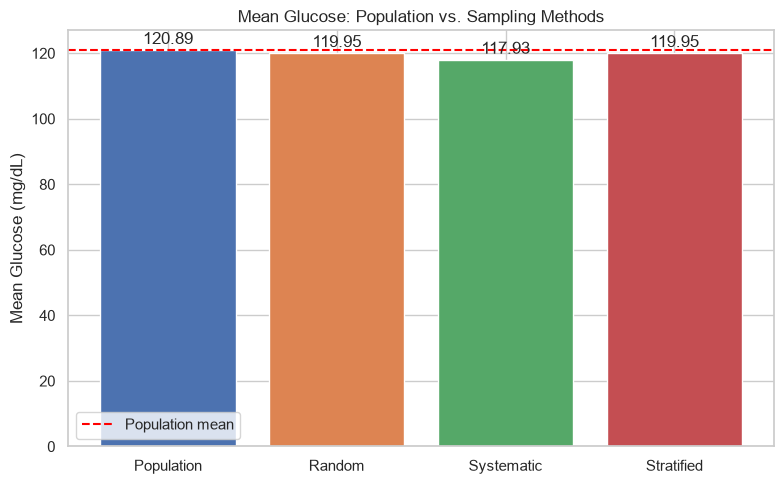

In [7]:
# ── Task 1: Sampling Methods ─────────────────────────────────────────────────
# Paste completed code from Module A, Task 1


import matplotlib.pyplot as plt

# 1. Collect the means
means_dict = {
    'Population': pop_mean_glucose,
    'Random': random_sample['Glucose'].mean(),
    'Systematic': systematic_sample['Glucose'].mean(),
    'Stratified': stratified_sample['Glucose'].mean(),
}

# 2. Plot the bars
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(means_dict.keys(), means_dict.values(),
              color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])

# 3. Reference line at the population mean
ax.axhline(pop_mean_glucose, linestyle='--', color='red', label='Population mean')

# 4. Axis label
ax.set_ylabel('Mean Glucose (mg/dL)')

# 5. Legend and title
ax.set_title('Mean Glucose: Population vs. Sampling Methods')
ax.legend()

# 6. Annotate each bar with its exact value
ax.bar_label(bars, fmt='%.2f', padding=2)

plt.tight_layout()
plt.show()


### Task 2: Sampling Bias & Sampling Distributions

Paste your completed Task 2 code and interpretation here.

*Member: Sahil Suryawanshi*

In [8]:
# ── Task 2 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

np.random.seed(42)  # RANDOM_STATE=42 used across all modules for consistency

# Extract Glucose as a NumPy array for efficient repeated sampling in the simulation below.
# We work with the raw column (including zeros) to show the real population distribution.
glucose_pop = df['Glucose'].values

print('Ready')


Ready


In [9]:
# Provided: demonstrate sampling bias by restricting the sampling frame

# --- Unbiased sample ---
# Drawn from the entire dataset, every patient has an equal chance of inclusion.
unbiased = df.sample(n=50, random_state=42)
unbiased_mean = unbiased['Glucose'].mean()

# --- Biased sample ---
# Only Diabetic patients are in the sampling frame.
# This simulates a real bias: e.g. only patients who visited a diabetes clinic were surveyed.
# The resulting mean will be systematically higher than the true population mean.
diabetic_only = df[df['Outcome'] == 1]
biased = diabetic_only.sample(n=50, random_state=42)
biased_mean = biased['Glucose'].mean()

pop_mean = df['Glucose'].mean()

print(f'True population mean      : {pop_mean:.2f} mg/dL')
print(f'Unbiased sample mean      : {unbiased_mean:.2f} mg/dL  (error: {abs(unbiased_mean-pop_mean):.2f})')
print(f'Biased sample mean        : {biased_mean:.2f} mg/dL  (error: {abs(biased_mean-pop_mean):.2f})')
print("==================================================================================================")
print('The biased sample overestimates the population mean because it only includes')
print('patients who already have diabetes (a classic sampling frame error).')


True population mean      : 120.89 mg/dL
Unbiased sample mean      : 123.04 mg/dL  (error: 2.15)
Biased sample mean        : 138.36 mg/dL  (error: 17.47)
The biased sample overestimates the population mean because it only includes
patients who already have diabetes (a classic sampling frame error).


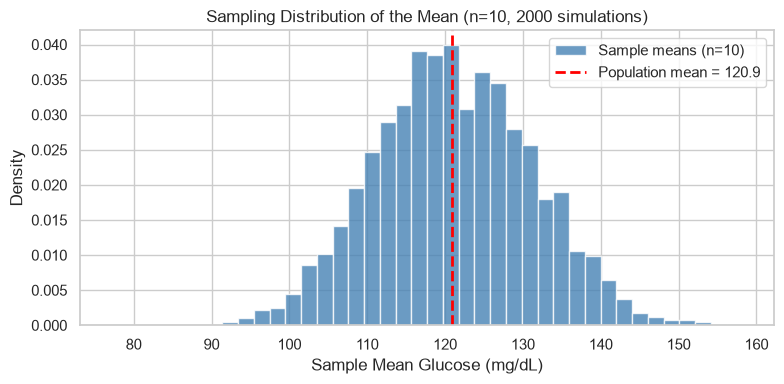

Mean of sample means : 121.10  (should be close to 120.89)
Std of sample means  : 10.15  (this is the Standard Error of the Mean)


In [10]:
# Provided: simulate a sampling distribution for n=10 to visualise spread

# --- What is a sampling distribution? ---
# If we repeated the sampling process many times, we would get a slightly different
# sample mean each time. The distribution of all those means is the 'sampling distribution'.
# As n increases, this distribution becomes narrower and more Normal (CLT, see Task 3).

N_SIMULATIONS = 2000   # number of times we repeat the sampling process
n = 10                 # sample size per draw, deliberately small to show high spread

# List comprehension: draw a random sample of size n, compute its mean, repeat 2000 times.
sample_means_10 = [
    np.random.choice(glucose_pop, size=n, replace=True).mean()
    for _ in range(N_SIMULATIONS)
]

fig, ax = plt.subplots(figsize=(8, 4))

# Plot the distribution of sample means as a histogram.
# kde=True overlays a smooth density curve so the shape is easier to read.
ax.hist(sample_means_10, bins=40, color='steelblue', edgecolor='white',
        alpha=0.8, density=True, label='Sample means (n=10)')

# Mark the true population mean with a vertical line for comparison.
ax.axvline(pop_mean, color='red', linestyle='--', linewidth=2,
           label=f'Population mean = {pop_mean:.1f}')

ax.set_title('Sampling Distribution of the Mean (n=10, 2000 simulations)')
ax.set_xlabel('Sample Mean Glucose (mg/dL)')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Mean of sample means : {np.mean(sample_means_10):.2f}  (should be close to {pop_mean:.2f})')
print(f'Std of sample means  : {np.std(sample_means_10):.2f}  (this is the Standard Error of the Mean)')


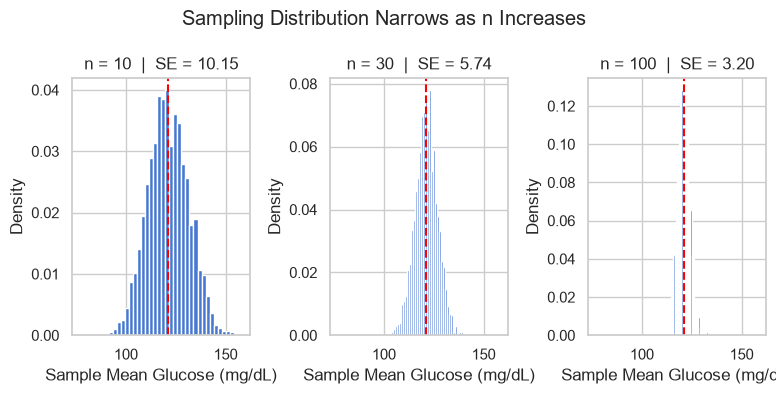

   n |  Mean of sample means |  Std of sample means (SE)
------------------------------------------------------------
  10 |                121.10 |                     10.15
  30 |                121.11 |                      5.74
 100 |                120.94 |                      3.20


In [11]:
# ── Task 2: Sampling Bias & Sampling Distributions ─────────────────────────
# Paste completed code from Module A, Task 2


N_SIMULATIONS = 2000
n=30
sample_means_30 = [
    np.random.choice(glucose_pop, size=n, replace=True).mean()
    for _ in range(N_SIMULATIONS)
]

n=100

sample_means_100 = [
    np.random.choice(glucose_pop, size=n, replace=True).mean()
    for _ in range(N_SIMULATIONS)
]


all_results = {
    10: sample_means_10,
    30: sample_means_30,
    100: sample_means_100,
}

fig, axes = plt.subplots(1,3,figsize=(8,4), sharex=True)

for ax, (n, means) in zip(axes, all_results.items()):
    ax.hist(means, bins=40, density=True)
    ax.axvline(pop_mean, linestyle='--', color='red')
    ax.set_title(f'n = {n}  |  SE = {np.std(means):.2f}')
    ax.set_xlabel('Sample Mean Glucose (mg/dL)')
    ax.set_ylabel('Density')

fig.suptitle('Sampling Distribution Narrows as n Increases')
plt.tight_layout()
plt.show()

print(f"{'n':>4} | {'Mean of sample means':>21} | {'Std of sample means (SE)':>25}")
print('-' * 60)
for n, means in all_results.items():
    print(f"{n:>4} | {np.mean(means):>21.2f} | {np.std(means):>25.2f}")

### Task 3: Central Limit Theorem Simulation

Paste your completed Task 3 code and interpretation here.

*Member: Hrithik Wadile*

In [12]:
# ── Task 3 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats   # scipy.stats: probability distributions, hypothesis tests, etc.

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (14, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)

np.random.seed(42)  # RANDOM_STATE=42 used across all modules

# Use Insulin, it is heavily right-skewed (many zeros/low values, long right tail).
# This makes the CLT result visually dramatic: the population is very non-Normal,
# yet the sample means converge to a Normal distribution.
insulin_pop = df['Insulin'].values   # shape: (768,)

print(f'Insulin population: n={len(insulin_pop)}, mean={insulin_pop.mean():.2f}, '
      f'skewness={stats.skew(insulin_pop):.2f}')
print('Ready')


Insulin population: n=768, mean=79.80, skewness=2.27
Ready


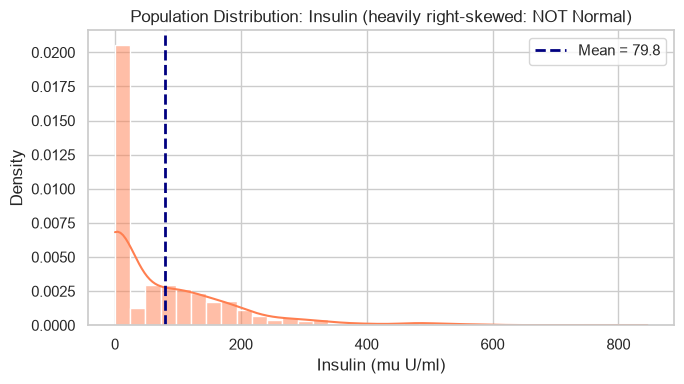

Skewness > 0 confirms right skew. The CLT will make sample means Normal despite this.


In [13]:
# Provided: plot the population distribution to confirm it is highly non-Normal

fig, ax = plt.subplots(figsize=(7, 4))

# sns.histplot with kde=True plots the histogram AND a smooth density curve.
# stat='density' scales the y-axis to probability density (area under the bar = 1),
# so the KDE and the histogram are on the same scale.
sns.histplot(insulin_pop, bins=35, kde=True, ax=ax,
             color='coral', stat='density')

ax.axvline(insulin_pop.mean(), color='navy', linestyle='--', linewidth=2,
           label=f'Mean = {insulin_pop.mean():.1f}')

ax.set_title('Population Distribution: Insulin (heavily right-skewed: NOT Normal)')
ax.set_xlabel('Insulin (mu U/ml)')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.show()

print('Skewness > 0 confirms right skew. The CLT will make sample means Normal despite this.')


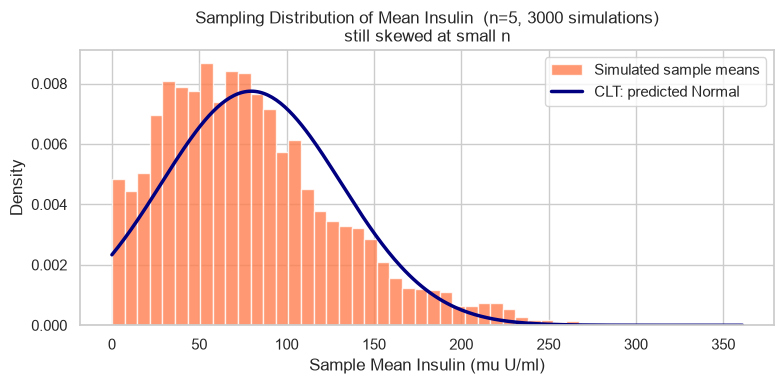

In [14]:
# Provided: CLT simulation for n=5 with theoretical Normal overlay

# --- CLT simulation ---
# We repeat 3000 times:
#   draw a sample of size n → compute its mean → record the mean.
# The histogram of all 3000 means is the sampling distribution.
# The CLT predicts this should look Normal with:
#   mean  = population mean (mu)
#   std   = population std / sqrt(n)   ← this is called the Standard Error (SE)

N_SIMS = 3000
n_demo = 5   # small sample: CLT is not yet fully active

means_n5 = np.array([
    np.random.choice(insulin_pop, size=n_demo, replace=True).mean()
    for _ in range(N_SIMS)
])

# Compute the theoretical Normal the CLT predicts.
mu_theory  = insulin_pop.mean()                   # CLT prediction: mean of sample means = population mean
se_theory  = insulin_pop.std() / np.sqrt(n_demo)  # CLT prediction: SE = sigma / sqrt(n)

# Create a range of x values for plotting the theoretical Normal curve.
x_range = np.linspace(means_n5.min(), means_n5.max(), 300)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(means_n5, bins=50, density=True, color='coral',
        edgecolor='white', alpha=0.8, label='Simulated sample means')

# Overlay the Normal PDF predicted by the CLT.
# stats.norm.pdf(x, loc=mu, scale=sigma) computes the Normal probability density at x.
ax.plot(x_range, stats.norm.pdf(x_range, mu_theory, se_theory),
        color='navy', linewidth=2.5, label='CLT: predicted Normal')

ax.set_title(f'Sampling Distribution of Mean Insulin  (n={n_demo}, {N_SIMS} simulations)\n'
             f'still skewed at small n')
ax.set_xlabel('Sample Mean Insulin (mu U/ml)')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.show()


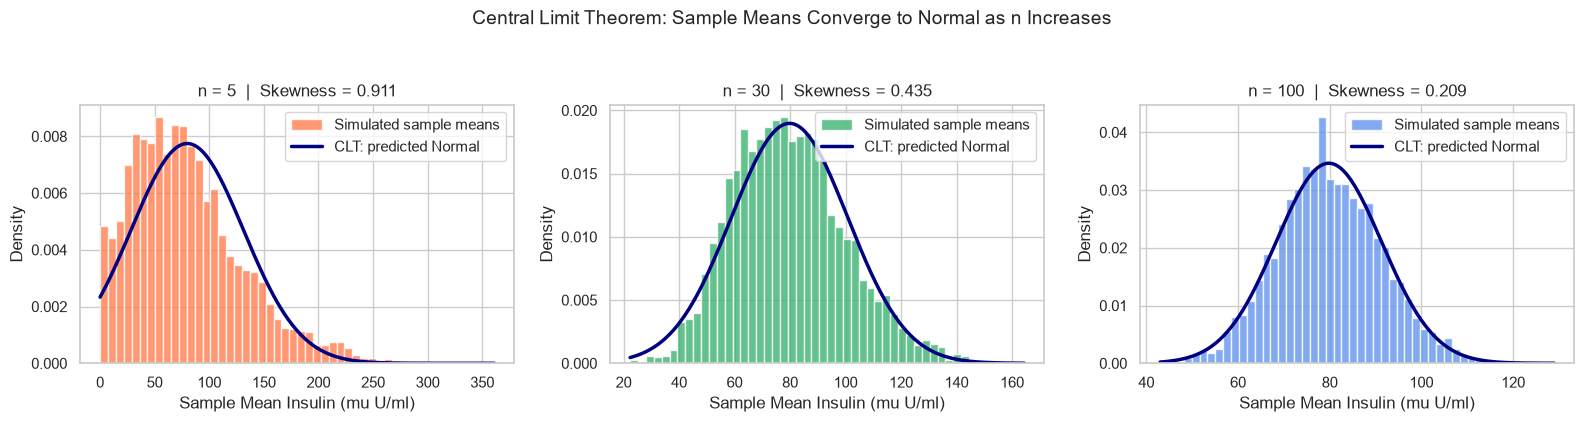

    n |  Empirical Mean |  Empirical SE |  Theoretical SE |  Skewness
----------------------------------------------------------------------
    5 |          79.521 |        51.444 |          51.505 |     0.911
   30 |          79.753 |        20.499 |          21.027 |     0.435
  100 |          79.979 |        11.551 |          11.517 |     0.209


In [15]:
# TODO: Repeat the CLT simulation for n=30 and n=100.
#       Plot them alongside the n=5 result so the convergence is visible.
#
# Steps:
#   1. Generate means_n30 and means_n100 using the same loop pattern as above.
#      Use N_SIMS=3000 and np.random.choice(insulin_pop, size=n, replace=True).
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

N_SIMS = 3000

# --- Step 1: generate sample means for n = 30 and n = 100 ---
n_demo_30 = 30
means_n30 = np.array([
    np.random.choice(insulin_pop, size=n_demo_30, replace=True).mean()
    for _ in range(N_SIMS)
])

n_demo_100 = 100
means_n100 = np.array([
    np.random.choice(insulin_pop, size=n_demo_100, replace=True).mean()
    for _ in range(N_SIMS)
])

# --- Step 2 & 3: one figure, three subplots ---
mu_theory = insulin_pop.mean()
sigma_pop = insulin_pop.std()

sample_sizes = [5, 30, 100]
all_means    = [means_n5, means_n30, means_n100]
colors       = ['coral', 'mediumseagreen', 'cornflowerblue']

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)

for ax, n, means, color in zip(axes, sample_sizes, all_means, colors):
    se_theory = sigma_pop / np.sqrt(n)          # SE depends on n!
    x_range = np.linspace(means.min(), means.max(), 300)

    ax.hist(means, bins=50, density=True, color=color,
            edgecolor='white', alpha=0.8, label='Simulated sample means')
    ax.plot(x_range, stats.norm.pdf(x_range, mu_theory, se_theory),
            color='navy', linewidth=2.5, label='CLT: predicted Normal')

    ax.set_title(f'n = {n}  |  Skewness = {stats.skew(means):.3f}')
    ax.set_xlabel('Sample Mean Insulin (mu U/ml)')
    ax.set_ylabel('Density')
    ax.legend()

fig.suptitle('Central Limit Theorem: Sample Means Converge to Normal as n Increases',
             fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# --- Step 4: summary table ---
print(f"{'n':>5} | {'Empirical Mean':>15} | {'Empirical SE':>13} | "
      f"{'Theoretical SE':>15} | {'Skewness':>9}")
print('-' * 70)
for n, means in zip(sample_sizes, all_means):
    emp_mean = means.mean()
    emp_se   = means.std()
    theo_se  = sigma_pop / np.sqrt(n)
    skew     = stats.skew(means)
    print(f"{n:>5} | {emp_mean:>15.3f} | {emp_se:>13.3f} | "
          f"{theo_se:>15.3f} | {skew:>9.3f}")
#   2. Create ONE figure with 3 subplots: plt.subplots(1, 3, figsize=(16, 4)).
#      For each subplot (n=5, n=30, n=100):
#        a. Plot the histogram of sample means (density=True, bins=50, edgecolor='white').
#        b. Overlay the CLT Normal curve using stats.norm.pdf().
#           Remember: SE = insulin_pop.std() / np.sqrt(n).
#        c. Title: f'n = {n}  |  Skewness = {stats.skew(means):.3f}'
#        d. Label axes consistently.




#   3. Add a suptitle: 'Central Limit Theorem: Sample Means Converge to Normal as n Increases'.
#
#   4. After the plot, print a table with columns:
#      n | Empirical Mean | Empirical SE | Theoretical SE | Skewness
#      for all three sample sizes.
#      (Theoretical SE = insulin_pop.std() / np.sqrt(n))

# YOUR CODE HERE


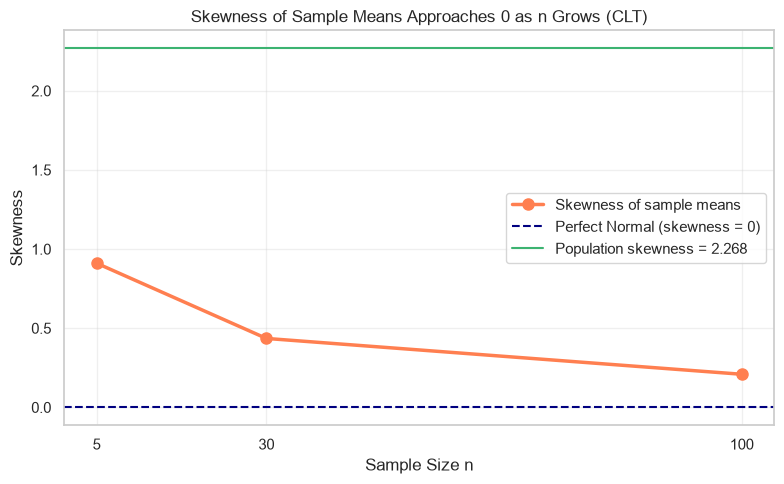

In [16]:
# TODO: Plot skewness vs sample size to make the CLT convergence quantitative.
#
# Steps:
#   1. Compute stats.skew() for means_n5, means_n30, and means_n100.
#   2. Also compute the skewness of the raw insulin_pop for comparison.
#   3. Create a line plot: x-axis = [5, 30, 100], y-axis = skewness of sample means.
#      Add a horizontal dashed line at y=0 (the skewness of a perfect Normal).
#   4. Mark the population skewness as a horizontal line of a different colour.
#   5. Title: 'Skewness of Sample Means Approaches 0 as n Grows (CLT)'.
#   6. Add appropriate axis labels and a legend.

# YOUR CODE HERE
# --- Step 1 & 2: compute skewness values ---
sample_sizes = [5, 30, 100]
skew_means = [stats.skew(means_n5),
              stats.skew(means_n30),
              stats.skew(means_n100)]

skew_pop = stats.skew(insulin_pop)

# --- Steps 3-6: line plot ---
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(sample_sizes, skew_means, marker='o', markersize=8,
        color='coral', linewidth=2.5, label='Skewness of sample means')

# Horizontal reference lines
ax.axhline(y=0, color='navy', linestyle='--', linewidth=1.5,
           label='Perfect Normal (skewness = 0)')
ax.axhline(y=skew_pop, color='mediumseagreen', linestyle='-', linewidth=1.5,
           label=f'Population skewness = {skew_pop:.3f}')

ax.set_title('Skewness of Sample Means Approaches 0 as n Grows (CLT)')
ax.set_xlabel('Sample Size n')
ax.set_ylabel('Skewness')
ax.set_xticks(sample_sizes)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


---
## Section B: Statistical Inference, Confidence Intervals & Hypothesis Testing
*Source: Module B (Week 1, Day 3)*

**Module Lead:** [Insert Module B member name]

Paste your completed **Tasks 4, 5, and 6** code cells and interpretation answers here.

### Task 4: Confidence Intervals

Paste your completed Task 4 code and interpretation here.

*Member: Akshay *

In [17]:
# Provided: construct a 95% CI for mean Glucose from a single sample of n=60

# Step 1: Draw a random sample of non-missing Glucose values.
glucose_clean = df['Glucose'].dropna()            # remove NaN rows before sampling
sample_glucose = glucose_clean.sample(n=60, random_state=42)

# Step 2: Compute the sample mean and standard error.
#   x_bar: our best single estimate of the population mean
#   se   : how much the sample mean would vary across repeated samples
#          SE = s / sqrt(n)  where s is the sample standard deviation (ddof=1)
x_bar = sample_glucose.mean()
se    = sample_glucose.std(ddof=1) / np.sqrt(len(sample_glucose))

# Step 3: Use the t-distribution (not Normal) to compute the CI.
#   Why t? Because we are estimating the population std from the sample.
#   For large n (>100) t ≈ z, but t is always the safer choice.
#   df = n - 1: degrees of freedom (one is 'used up' estimating the mean)
#   loc = x_bar: centre of the distribution
#   scale = se : standard deviation of the sampling distribution
ci_low, ci_high = stats.t.interval(
    confidence=0.95,
    df=len(sample_glucose) - 1,
    loc=x_bar,
    scale=se
)

true_mean_glucose = glucose_clean.mean()   # benchmark: the 'true' population mean

print('--- 95% Confidence Interval for Mean Glucose (sample n=60) ---')
print(f'Sample mean        : {x_bar:.2f} mg/dL')
print(f'95% CI             : [{ci_low:.2f}, {ci_high:.2f}] mg/dL')
print(f'CI width           : {ci_high - ci_low:.2f} mg/dL')
print(f'True population mean: {true_mean_glucose:.2f} mg/dL')
print(f'Does the CI contain the true mean? {ci_low <= true_mean_glucose <= ci_high}')


--- 95% Confidence Interval for Mean Glucose (sample n=60) ---
Sample mean        : 123.42 mg/dL
95% CI             : [115.23, 131.60] mg/dL
CI width           : 16.37 mg/dL
True population mean: 120.89 mg/dL
Does the CI contain the true mean? True


Ready
sample mean:35.202 mg/dL
CI bounds: [33.39, 37.02] mg/dL
CI width : 3.63 mg/dL
True population mean: 120.89 mg/dL
Does the CI contain the true mean? False


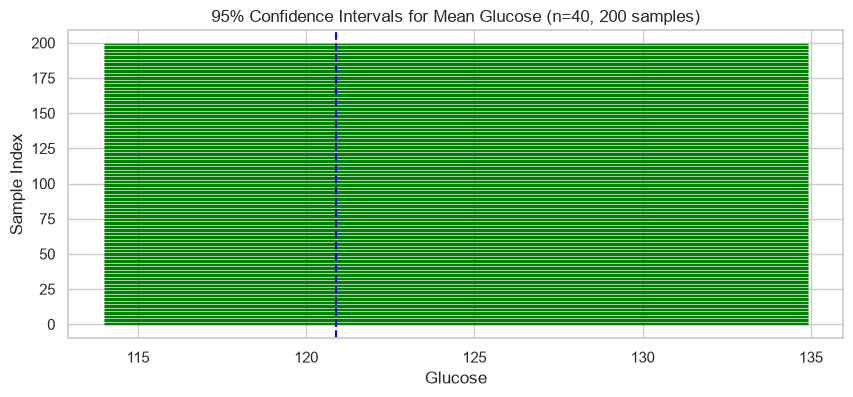

Empirical coverage: 100.0% of CIs contained the true mean.


In [18]:
# ── Task 4: Confidence Intervals ────────────────────────────────────────────
# Paste completed code from Module B, Task 4
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats   # stats.t.interval: computes exact t-based confidence intervals

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Replace impossible zeros in clinical measurements with NaN.
# A Glucose or BMI of 0 is physically impossible: these are missing values disguised as zeros.
# We must remove them BEFORE computing any CIs or tests, or the results will be distorted.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

np.random.seed(42)  # RANDOM_STATE=42 used across all modules for consistency
print('Ready')

filters=df[(df['Outcome'] == 1) & (df['BMI'].notna())]['BMI']
sample_bmi = filters.sample(n=50, random_state=42)
x_bar = sample_bmi.mean()
se=sample_bmi.std(ddof=1) / np.sqrt(len(sample_bmi))
ci_low, ci_high = stats.t.interval(confidence=0.95,df=len(sample_bmi) - 1,loc=x_bar,scale=se)
true_mean_bmi_diabetic = filters.mean()
print(f'sample mean:{x_bar} mg/dL')
print(f'CI bounds: [{ci_low:.2f}, {ci_high:.2f}] mg/dL')
print(f'CI width : {ci_high - ci_low:.2f} mg/dL')
print(f'True population mean: {true_mean_glucose:.2f} mg/dL')
print(f'Does the CI contain the true mean? {ci_low <= true_mean_glucose <= ci_high}')

true_mean = glucose_clean.mean()
results = []
for i in range(200):
    gluco = glucose_clean.sample(n=40, random_state=42)
    x_bar = gluco.mean()
    se = gluco.std(ddof=1) / np.sqrt(len(gluco))
    ci_low, ci_high = stats.t.interval(confidence=0.95, df=len(gluco) - 1, loc=x_bar, scale=se)
    results.append((ci_low, ci_high, ci_low <= true_mean <= ci_high))

plt.hlines(y=range(200), xmin=[r[0] for r in results], xmax=[r[1] for r in results],
           colors=['green' if r[2] else 'red' for r in results], linewidth=1)
plt.axvline(x=true_mean, color='blue', linestyle='--')
plt.title('95% Confidence Intervals for Mean Glucose (n=40, 200 samples)')
plt.xlabel('Glucose')
plt.ylabel('Sample Index')
plt.show()
coverage = sum(r[2] for r in results) / len(results) * 100
print(f'Empirical coverage: {coverage}% of CIs contained the true mean.')



### Task 5: Hypothesis Testing (t-test & ANOVA)

Paste your completed Task 5 code and interpretation here.

*Member: ____Frederick____________*

In [19]:
# ── Task 5 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

# Clean impossible zeros before any inferential test.
# Zeros in these columns are missing values that would corrupt the test statistics.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

# Create three age groups for the ANOVA in this task.
# pd.cut() divides a continuous variable into labelled intervals.
# right=True means the interval is (lower, upper]: the upper bound is included.
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[20, 35, 50, 82],
    labels=['Young (21-35)', 'Middle (36-50)', 'Senior (51+)'],
    right=True
)

print('Age group distribution:')
print(df['AgeGroup'].value_counts().sort_index())
print('Ready')


Age group distribution:
AgeGroup
Young (21-35)     498
Middle (36-50)    189
Senior (51+)       81
Name: count, dtype: int64
Ready


--- Group descriptives ---
Diabetic        n=266  mean=142.32  std=29.60
Non-Diabetic    n=497  mean=110.64  std=24.78

--- Welch t-test: Glucose ---
t-statistic : 14.8844
p-value     : 2.84e-41

Conclusion: p=2.84e-41 < α=0.05 → Reject H₀.
The data provide strong evidence that mean Glucose differs between groups.
(Note: this does NOT prove that high Glucose CAUSES diabetes.)


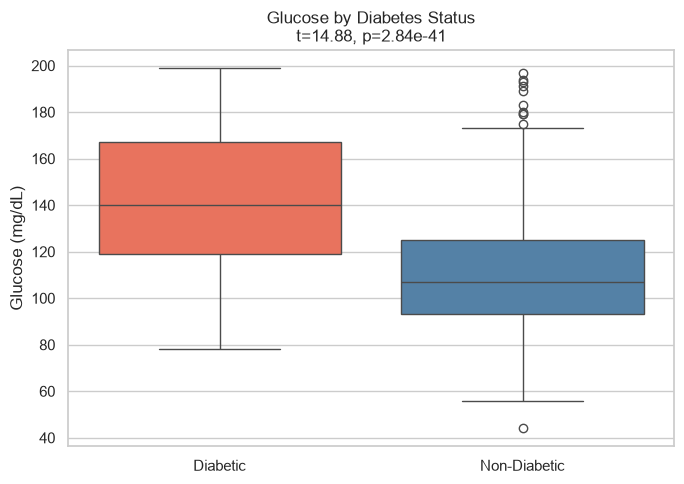

In [20]:
# Provided: independent t-test Glucose: Diabetic vs Non-Diabetic

# --- Hypotheses ---
# H₀: Mean Glucose is the same in Diabetic and Non-Diabetic patients.
# H₁: Mean Glucose differs between the two groups.

# Separate the two groups and drop NaN values.
# dropna() is essential: stats.ttest_ind cannot handle NaN and will return NaN results.
group_diab     = df.loc[df['Outcome'] == 1, 'Glucose'].dropna()
group_nondiab  = df.loc[df['Outcome'] == 0, 'Glucose'].dropna()

print('--- Group descriptives ---')
for name, grp in [('Diabetic', group_diab), ('Non-Diabetic', group_nondiab)]:
    print(f'{name:<14}  n={len(grp)}  mean={grp.mean():.2f}  std={grp.std():.2f}')

# Run Welch's t-test (equal_var=False).
# Welch's version does NOT assume equal variances in both groups.
t_stat, p_value = stats.ttest_ind(group_diab, group_nondiab, equal_var=False)

print('\n--- Welch t-test: Glucose ---')
print(f't-statistic : {t_stat:.4f}')
print(f'p-value     : {p_value:.2e}')

alpha = 0.05
if p_value < alpha:
    print(f'\nConclusion: p={p_value:.2e} < α={alpha} → Reject H₀.')
    print('The data provide strong evidence that mean Glucose differs between groups.')
    print('(Note: this does NOT prove that high Glucose CAUSES diabetes.)')
else:
    print(f'\nConclusion: p={p_value:.2e} ≥ α={alpha} → Fail to reject H₀.')

# Visualise with a boxplot: shows median, spread, and outliers at a glance.
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df.dropna(subset=['Glucose']), x='DiabetesStatus', y='Glucose',
            palette={'Non-Diabetic': 'steelblue', 'Diabetic': 'tomato'}, ax=ax)
ax.set_title(f'Glucose by Diabetes Status\nt={t_stat:.2f}, p={p_value:.2e}')
ax.set_xlabel('')
ax.set_ylabel('Glucose (mg/dL)')
plt.tight_layout()
plt.show()


--- Group descriptives ---
Diabetic        n=266  mean=35.41  std=6.61
Non-Diabetic    n=491  mean=30.86  std=6.56

--- Welch t-test: BMI ---
t-statistic : 9.0550
p-value     : 2.48e-18

Conclusion: p=2.48e-18 < α=0.05 → Reject H₀.
The data provide strong evidence that mean BMI differs between groups.
(Note: this does NOT prove that high BMI CAUSES diabetes.)


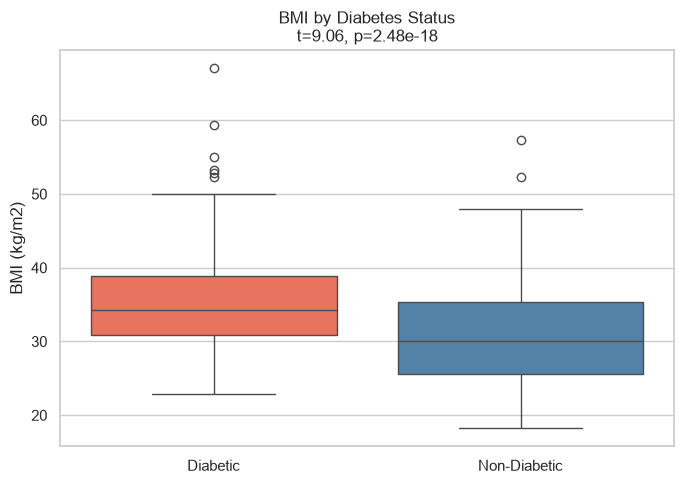

In [21]:
# ── Task 5: Hypothesis Testing, t-test & ANOVA ──────────────────────────────
# Paste completed code from Module B, Task 5
# TODO: Run the same t-test comparing BMI between Diabetic and Non-Diabetic patients.
#
# Steps (mirror the Glucose t-test above exactly):
#   1. Extract group_diab_bmi and group_nondiab_bmi from the BMI column, dropping NaN.
#   2. Print group descriptives (n, mean, std) for both groups.
#   3. State H₀ and H₁ as print statements.
#   4. Run stats.ttest_ind(..., equal_var=False).
#   5. Print t-statistic, p-value, and a conclusion sentence.
#   6. Plot a side-by-side boxplot of BMI by DiabetesStatus.

# YOUR CODE HERE

# Provided: independent t-test Glucose: Diabetic vs Non-Diabetic

# --- Hypotheses ---
# H₀: Mean Glucose is the same in Diabetic and Non-Diabetic patients.
# H₁: Mean Glucose differs between the two groups.

# Separate the two groups and drop NaN values.
# dropna() is essential: stats.ttest_ind cannot handle NaN and will return NaN results.
group_diab_bmi     = df.loc[df['Outcome'] == 1, 'BMI'].dropna()
group_nondiab_bmi  = df.loc[df['Outcome'] == 0, 'BMI'].dropna()

print('--- Group descriptives ---')
for name, grp in [('Diabetic', group_diab_bmi), ('Non-Diabetic', group_nondiab_bmi)]:
    print(f'{name:<14}  n={len(grp)}  mean={grp.mean():.2f}  std={grp.std():.2f}')

# Run Welch's t-test (equal_var=False).
# Welch's version does NOT assume equal variances in both groups.
t_stat, p_value = stats.ttest_ind(group_diab_bmi, group_nondiab_bmi, equal_var=False)

print('\n--- Welch t-test: BMI ---')
print(f't-statistic : {t_stat:.4f}')
print(f'p-value     : {p_value:.2e}')

alpha = 0.05
if p_value < alpha:
    print(f'\nConclusion: p={p_value:.2e} < α={alpha} → Reject H₀.')
    print('The data provide strong evidence that mean BMI differs between groups.')
    print('(Note: this does NOT prove that high BMI CAUSES diabetes.)')
else:
    print(f'\nConclusion: p={p_value:.2e} ≥ α={alpha} → Fail to reject H₀.')

# Visualise with a boxplot: shows median, spread, and outliers at a glance.
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df.dropna(subset=['BMI']), x='DiabetesStatus', y='BMI',
            palette={'Non-Diabetic': 'steelblue', 'Diabetic': 'tomato'}, ax=ax)
ax.set_title(f'BMI by Diabetes Status\nt={t_stat:.2f}, p={p_value:.2e}')
ax.set_xlabel('')
ax.set_ylabel('BMI (kg/m2)')
plt.tight_layout()
plt.show()


--- Hypotheses ---
H₀: Mean Glucose is the same across all age groups.
H₁: At least one age group has a different mean Glucose.

--- Group descriptives ---
Young    n=495  mean=116.50  std=28.02
Middle   n=187  mean=127.62  std=32.67
Senior   n=81  mean=139.68  std=31.26

--- One-Way ANOVA: Glucose by Age Group ---
F-statistic : 26.3765
p-value     : 8.41e-12

Conclusion: p=8.41e-12 < α=0.05 → Reject H₀.
There is strong evidence that mean Glucose differs among the age groups.


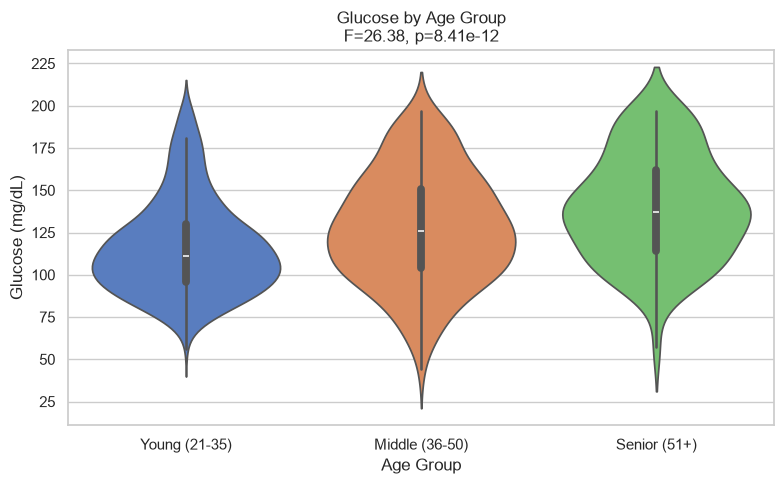

In [22]:
# TODO: One-way ANOVA: test whether mean Glucose differs across the three age groups.
#
# Why ANOVA instead of multiple t-tests?
# Running three separate t-tests (Young vs Middle, Young vs Senior, Middle vs Senior)
# inflates the false-positive rate. With α=0.05, three tests give a ~14% chance of at
# least one false positive. ANOVA controls this by testing all groups simultaneously.
#
# Steps:
#   1. Create three arrays: glucose for Young, Middle, Senior: each with NaN dropped.
#      Use df.loc[df['AgeGroup'] == 'Young (21-35)', 'Glucose'].dropna()
#   2. Print group descriptives (n, mean, std) for all three groups.
#   3. State H₀ and H₁ as print statements.
#   4. Run stats.f_oneway(young_glucose, middle_glucose, senior_glucose).
#      This returns (F_statistic, p_value).
#   5. Print F-statistic, p-value, and a one-sentence conclusion.
#   6. Plot a violin plot (sns.violinplot) of Glucose by AgeGroup.
#      A violin plot shows both the distribution shape and the median, making it
#      more informative than a boxplot for ANOVA visualisation.

# YOUR CODE HERE
# --- Hypotheses ---
print('--- Hypotheses ---')
print('H₀: Mean Glucose is the same across all age groups.')
print('H₁: At least one age group has a different mean Glucose.\n')

# Separate glucose values for each age group and drop missing values
young_glucose = df.loc[df['AgeGroup'] == 'Young (21-35)', 'Glucose'].dropna()
middle_glucose = df.loc[df['AgeGroup'] == 'Middle (36-50)', 'Glucose'].dropna()
senior_glucose = df.loc[df['AgeGroup'] == 'Senior (51+)', 'Glucose'].dropna()

# Print descriptive statistics
print('--- Group descriptives ---')
for name, grp in [('Young', young_glucose),
                  ('Middle', middle_glucose),
                  ('Senior', senior_glucose)]:
    print(f'{name:<8} n={len(grp)}  mean={grp.mean():.2f}  std={grp.std():.2f}')

# Run One-Way ANOVA
F_stat, p_value = stats.f_oneway(
    young_glucose,
    middle_glucose,
    senior_glucose
)

print('\n--- One-Way ANOVA: Glucose by Age Group ---')
print(f'F-statistic : {F_stat:.4f}')
print(f'p-value     : {p_value:.2e}')

alpha = 0.05

if p_value < alpha:
    print(f'\nConclusion: p={p_value:.2e} < α={alpha} → Reject H₀.')
    print('There is strong evidence that mean Glucose differs among the age groups.')
else:
    print(f'\nConclusion: p={p_value:.2e} ≥ α={alpha} → Fail to reject H₀.')
    print('There is insufficient evidence that mean Glucose differs among the age groups.')

# Violin plot
fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=df.dropna(subset=['Glucose']),
    x='AgeGroup',
    y='Glucose',
    palette='muted',
    ax=ax
)

ax.set_title(f'Glucose by Age Group\nF={F_stat:.2f}, p={p_value:.2e}')
ax.set_xlabel('Age Group')
ax.set_ylabel('Glucose (mg/dL)')

plt.tight_layout()
plt.show()

### ✍️ Interpretation: Task 5

1. The Glucose t-test produced an extremely small p-value (e.g. 1e-22). Does this mean the difference is clinically *important*? What additional measure would you report to assess practical significance?
2. For the BMI t-test: state the result in one non-technical sentence that a doctor could understand (avoid the word 'p-value').
3. The ANOVA tells you *that* at least one age group differs in mean Glucose, but not *which* groups. What is the name of the follow-up procedure used to identify which specific pairs differ?

> *Your answer here:*
1. A very small p-value does not necessarily mean the difference is clinically important. It only indicates that the observed difference is unlikely to be due to chance. To assess practical or clinical significance, I would report a 95% confidence interval for the difference in mean glucose levels.
2. Patients with diabetes had a higher average BMI than patients without diabetes, suggesting that higher body weight is associated with diabetes in this dataset.
3. The follow-up procedure is called a post hoc test, which essentially compares age groups with a significant difference

### Task 6: Statistical Testing Conclusions

Paste your completed Task 6 code and interpretation here.

*Member: Akshay ,Fredrick*

Ready


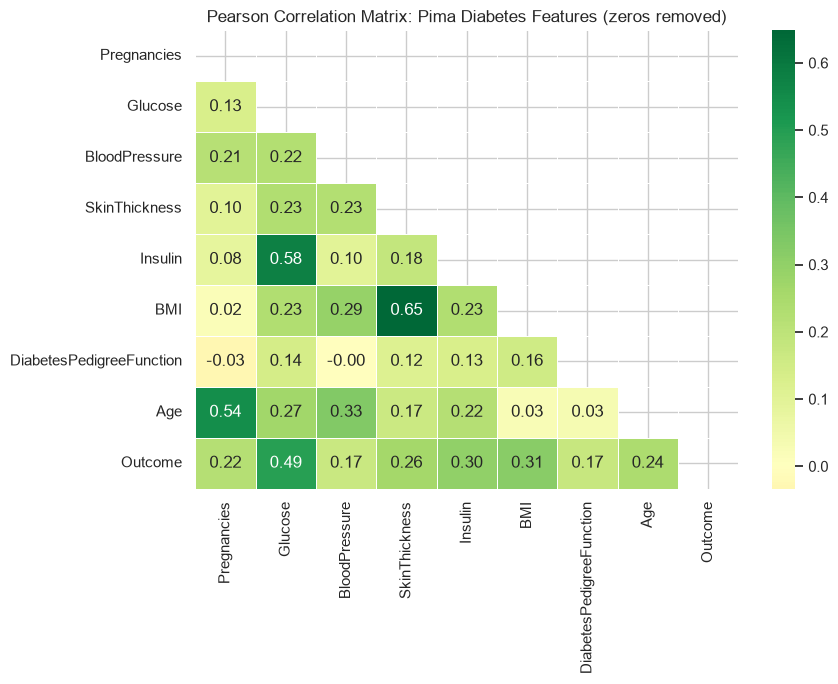


Features ranked by |r| with Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Pearson correlation coefficient (r): 0.2328
p-value: 0.0000
The correlation is moderate.


Text(0.5, 0, 'Glucose (mg/dL)')

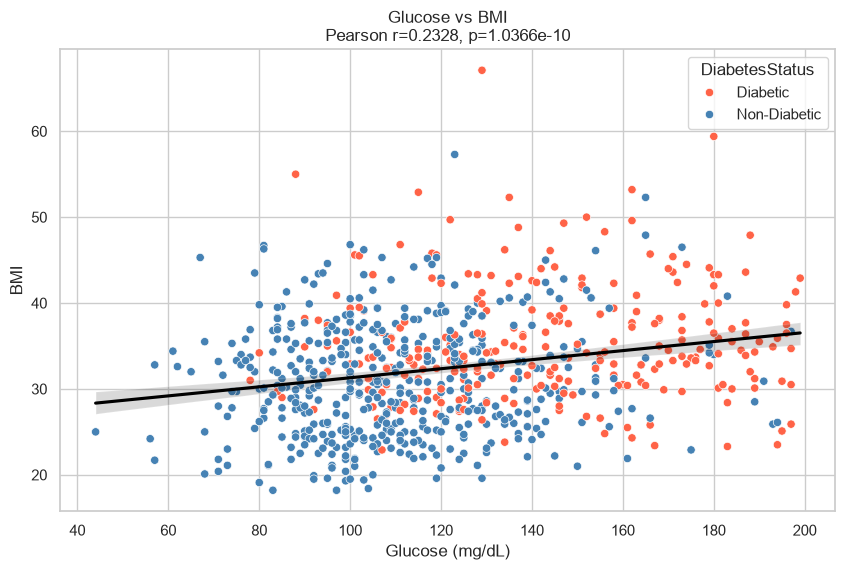

In [23]:
# ── Task 6: Statistical Testing Conclusions ────────────────────────────────
# Paste completed code from Module B, Task 6
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)

# Numeric columns for the correlation matrix (exclude the string 'DiabetesStatus' column).
NUMERIC_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
                'Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']

print('Ready')
# Provided: Pearson correlation matrix heatmap

# df.corr() computes Pearson r for every pair of numeric columns.
# NaN values are dropped pairwise, each pair uses all rows where both values are present.
corr_matrix = df[NUMERIC_COLS].corr()

# Create an upper-triangle mask so we only display the lower half of the matrix.
# The matrix is symmetric (r(X,Y) = r(Y,X)), so the upper half is redundant.
upper_tri = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    mask=upper_tri,    # hide the upper triangle
    annot=True,        # print r values inside each cell
    fmt='.2f',         # format to 2 decimal places
    cmap='RdYlGn',     # red = negative, yellow = near zero, green = positive
    center=0,          # white at r=0 for easy visual interpretation
    linewidths=0.5,    # thin lines between cells
    ax=ax
)
ax.set_title('Pearson Correlation Matrix: Pima Diabetes Features (zeros removed)')
plt.tight_layout()
plt.show()

# Rank all features by their absolute correlation with the target (Outcome).
outcome_corr = corr_matrix['Outcome'].drop('Outcome').abs().sort_values(ascending=False)
print('\nFeatures ranked by |r| with Outcome:')
print(outcome_corr.round(3).to_string())
# TODO: Formal Pearson correlation test between Glucose and BMI.
#
# Unlike df.corr() (which only gives r), stats.pearsonr() also gives the p-value,
# which tells us whether the correlation is statistically distinguishable from zero.
#
# Steps:
#   1. Drop rows where EITHER Glucose OR BMI is NaN.
#      Use df.dropna(subset=['Glucose', 'BMI']).
#   2. Run stats.pearsonr(x, y), it returns (r, p_value).
#   3. Print: r rounded to 4 decimal places, p-value, and a plain-English conclusion.
#      Include: is |r| small (< 0.1), moderate (0.1–0.3), or strong (> 0.3)?
#   4. Create a scatter plot (Glucose on x-axis, BMI on y-axis):
#        - Colour points by DiabetesStatus (use hue= in sns.scatterplot).
#        - Overlay a linear trend line using sns.regplot() with scatter=False.
#        - Add r and p-value to the title.

# YOUR CODE HERE
gluc_bmi = df.dropna(subset=['Glucose', 'BMI'])
r, p_value = stats.pearsonr(gluc_bmi['Glucose'], gluc_bmi['BMI'])
print(f'Pearson correlation coefficient (r): {r:.4f}')
print(f'p-value: {p_value:.4f}')
if abs(r) < 0.1:
    strength = 'small'
elif abs(r) >= 0.1 and abs(r) <= 0.3:
    strength = 'moderate'
else:
    strength = 'strong'
print(f'The correlation is {strength}.')

# Scatter plot with regression line
plt.figure(figsize=(10, 6))
sns.scatterplot(data=gluc_bmi, x='Glucose', y='BMI', hue='DiabetesStatus',
                 palette={'Non-Diabetic': 'steelblue', 'Diabetic': 'tomato'})
sns.regplot(data=gluc_bmi, x='Glucose', y='BMI', scatter=False, color='black',
            line_kws={'label':"Linear Fit"})
plt.title(f'Glucose vs BMI\nPearson r={r:.4f}, p={p_value:.4e}')
plt.xlabel('Glucose (mg/dL)')




In [24]:
# TODO: Build a ranked correlation table, all features vs Outcome.
#
# For each feature in NUMERIC_COLS (excluding 'Outcome'), compute:
#   - Pearson r vs Outcome using stats.pearsonr()
#   - the corresponding p-value
#   - a boolean: is p < 0.05?
#
# Steps:
#   1. Start with an empty list called records.
#   2. Loop over each feature in NUMERIC_COLS (skip 'Outcome'):
#        a. Drop NaN in both the feature and 'Outcome' column simultaneously.
#        b. Run stats.pearsonr().
#        c. Append a dict {'Feature': ..., 'r': ..., 'p-value': ...,
#                          'Significant (α=0.05)': ...} to records.
#   3. Create a DataFrame from records.
#   4. Sort by absolute r value (descending).
#   5. Round r to 4 dp and p-value to 6 dp.
#   6. Print the full table.

# YOUR CODE HERE

# Build a ranked correlation table: all features vs Outcome

# Step 1: Create an empty list
records = []

# Step 2: Loop through each feature (excluding Outcome)
for feature in NUMERIC_COLS:
    if feature == 'Outcome':
        continue

    # Drop rows with missing values in either column
    temp = df[[feature, 'Outcome']].dropna()

    # Compute Pearson correlation and p-value
    r, p = stats.pearsonr(temp[feature], temp['Outcome'])

    # Store the results
    records.append({
        'Feature': feature,
        'r': r,
        'p-value': p,
        'Significant (α=0.05)': p < 0.05
    })

# Step 3: Convert to DataFrame
corr_table = pd.DataFrame(records)

# Step 4: Sort by absolute correlation (largest first)
corr_table = corr_table.reindex(
    corr_table['r'].abs().sort_values(ascending=False).index
)

# Step 5: Round values
corr_table['r'] = corr_table['r'].round(4)
corr_table['p-value'] = corr_table['p-value'].round(6)

# Step 6: Print the full table
print("\nRanked Pearson Correlation with Outcome")
print(corr_table.to_string(index=False))


Ranked Pearson Correlation with Outcome
                 Feature      r  p-value  Significant (α=0.05)
                 Glucose 0.4947 0.000000                  True
                     BMI 0.3137 0.000000                  True
                 Insulin 0.3035 0.000000                  True
           SkinThickness 0.2595 0.000000                  True
                     Age 0.2384 0.000000                  True
             Pregnancies 0.2219 0.000000                  True
DiabetesPedigreeFunction 0.1738 0.000001                  True
           BloodPressure 0.1706 0.000003                  True


---
## Section C: ML Foundations, Data Preparation & Feature Engineering
*Source: Module C (Week 2, Day 1)*

**Module Lead:** [Insert Module C member name]

Paste your completed **Tasks 7, 8, and 9** code cells and interpretation answers here.

### Task 7: Types of Machine Learning & Identifying the Task

Paste your completed Task 7 code and interpretation here.

*Member: _Akshay_______________*

In [25]:
# ── Task 7 Setup (do not modify) ──────────────────────────────────────────────

# pandas: DataFrames, reading CSV, groupby, filtering
import pandas as pd

# numpy: numerical arrays and mathematical operations
import numpy as np

# matplotlib + seaborn: plotting
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(URL)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')


Dataset loaded: 768 rows x 10 columns


In [26]:
# Provided: classify the ML problem type and define X and y

# --- ML Problem Classification ---
# The lecture defined three types:
#   Supervised     → labelled data, learn input→output (classification or regression)
#   Unsupervised   → no labels, discover patterns (clustering, dimensionality reduction)
#   Reinforcement  → agent learns via rewards/penalties (game AI, robotics)
#
# The Diabetes dataset HAS labels (Outcome: 0/1, whether the patient has diabetes).
# We want to PREDICT the label from the other columns.
# → This is SUPERVISED LEARNING, specifically BINARY CLASSIFICATION.

print('ML Problem Type: Supervised Learning, Binary Classification')
print('  Reason: We have labelled examples (Outcome = 0 or 1) and want to')
print('          predict the label for new, unseen patients.')
print()

# --- Define features (X) and target (y) ---
# X contains all input columns: the information available at prediction time.
# y contains the label we want to predict.
# We exclude 'DiabetesStatus' because it is derived from Outcome: not an independent feature.
FEATURE_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
                'Insulin','BMI','DiabetesPedigreeFunction','Age']

X = df[FEATURE_COLS]   # shape: (768, 8) the input features
y = df['Outcome']      # shape: (768,)   the binary target label

print(f'X shape: {X.shape}  (rows=patients, cols=features)')
print(f'y shape: {y.shape}  (0=Non-Diabetic, 1=Diabetic)')
print(f'\nFeatures used: {FEATURE_COLS}')


ML Problem Type: Supervised Learning, Binary Classification
  Reason: We have labelled examples (Outcome = 0 or 1) and want to
          predict the label for new, unseen patients.

X shape: (768, 8)  (rows=patients, cols=features)
y shape: (768,)  (0=Non-Diabetic, 1=Diabetic)

Features used: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64%


Text(0, 0.5, 'Count')

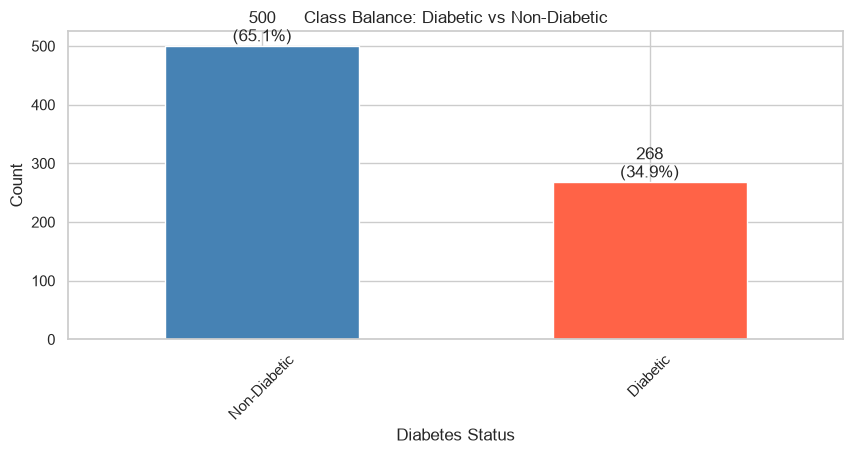

In [27]:
# TODO: Check and visualise the class balance of the target variable y.
#
# Class imbalance matters: if 90% of patients are Non-Diabetic, a model that always
# predicts 'Non-Diabetic' will achieve 90% accuracy without learning anything.
#
# Steps:
#   1. Print the count of each class: y.value_counts()
#   2. Print the percentage split: y.value_counts(normalize=True) * 100, rounded to 1 dp.
#   3. Create a bar chart showing the count of Diabetic vs Non-Diabetic patients.
#      Use df['DiabetesStatus'].value_counts().plot(kind='bar', ...).
#      Colour bars: Non-Diabetic='steelblue', Diabetic='tomato'.
#   4. Annotate each bar with its count and percentage.
#   5. Add a title: 'Class Balance: Diabetic vs Non-Diabetic' and rotate x-axis labels.

# YOUR CODE HERE
print(y.value_counts())
print(f"{(y.value_counts(normalize=True) * 100).round(1)}%")
counts=df['DiabetesStatus'].value_counts()
ax = counts.plot(kind='bar', color=['steelblue', 'tomato'])
total = counts.sum()
for i, count in enumerate(counts):
    percentage = (count / total) * 100
    ax.text(i,count,f"{count}\n({percentage:.1f}%)",ha="center",va="bottom")
plt.title('Class Balance: Diabetic vs Non-Diabetic')
plt.xticks(rotation=45)
plt.xlabel('Diabetes Status')
plt.ylabel('Count')

In [28]:
# TODO: Complete the ML workflow classification table.
#
# Replace each '???' with the correct answer for the Diabetes dataset.
# The table maps the 10-step ML workflow from the lecture to this specific project.
# This is only an illustrative example (no actual training is needed at the moment).

workflow = {
    'Step 1 Problem Definition':  {'Our answer': 'Predict whether a patient has diabetes or not using clinical features. This is a binary classification problem.'},
    # e.g. 'Predict whether a patient has diabetes (binary classification)'

    'Step 2 Data Collection':     {'Our answer': 'Use the Diabetes dataset with patient health measurements such as Glucose, BMI, Age, BloodPressure, and Outcome.'},
    # e.g. 'Pima Indians Diabetes dataset from openml.org (768 patients)'

    'Step 3 Data Preprocessing':  {'Our answer': 'Check missing values, handle impossible zero values if needed, create DiabetesStatus from Outcome, and prepare the data for modelling.'},
    # e.g. 'Replace impossible zeros with NaN, then impute'

    'Step 4 Feature Selection':   {'Our answer': 'Use the main clinical features as input variables and remove target/derived columns such as Outcome and DiabetesStatus from X'},
    # e.g. 'All 8 clinical features; remove DiabetesStatus (derived column)'

    'Step 5 Data Splitting':      {'Our answer': 'Split the data into training and testing sets, for example 80% train and 20% test, preferably stratified by Outcome.'},
    # e.g. '80% train / 20% test, stratified on Outcome'

    'Step 6 Model Selection':     {'Our answer': 'Choose a classification model such as Logistic Regression, Decision Tree, Random Forest, or KNN.'},
    # e.g. 'To be decided in Module D (linear/logistic regression)'

    'Step 7 Model Training':      {'Our answer': 'Train the selected model using only the training data.'},
    # e.g. 'Fit model on training set only'

    'Step 8 Evaluation':          {'Our answer': 'Evaluate the model on the test set using classification metrics such as accuracy, precision, recall, F1-score, and confusion matrix'},
    # e.g. 'Assess on test set using MAE/MSE/R² (regression) or accuracy (classification)'

    'Step 9 Hyperparameter Tuning': {'Our answer': 'Use cross-validation or GridSearchCV to find the best model settings, such as regularisation strength or tree depth.'},
    # e.g. 'Cross-validation to optimise regularisation strength'

    'Step 10 Deployment':         {'Our answer': 'Deploy the model as a simple app or API where users can enter patient values and get a diabetes prediction or risk score.'},
    # e.g. 'Serve via API so clinicians can input patient values and get a risk score'
}

workflow_df = pd.DataFrame(workflow).T
print(workflow_df.to_string())


                                                                                                                                                          Our answer
Step 1 Problem Definition                            Predict whether a patient has diabetes or not using clinical features. This is a binary classification problem.
Step 2 Data Collection                              Use the Diabetes dataset with patient health measurements such as Glucose, BMI, Age, BloodPressure, and Outcome.
Step 3 Data Preprocessing     Check missing values, handle impossible zero values if needed, create DiabetesStatus from Outcome, and prepare the data for modelling.
Step 4 Feature Selection               Use the main clinical features as input variables and remove target/derived columns such as Outcome and DiabetesStatus from X
Step 5 Data Splitting                           Split the data into training and testing sets, for example 80% train and 20% test, preferably stratified by Outcome.
Step 6 Mod

### Task 8: Handling Missing Values, Noise & Outliers

Paste your completed Task 8 code and interpretation here.

*Member: _Fredrick_______________*

In [29]:
# ── Task 8: Handling Missing Values, Noise & Outliers ──────────────────────
# Paste completed code from Module C, Task 8
# ── Task 8 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'

# Load as 'raw', this is the unmodified original with impossible zeros.
# We keep this separate so that we can always compare raw vs cleaned results.
df_raw = pd.read_csv(URL)

# These five columns contain clinically impossible zeros, they represent missing measurements.
# 'Pregnancies' and 'Age' can legitimately be zero so they are NOT in this list.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print('Ready')


Ready


In [30]:
# Provided: replace zeros with NaN, then apply MEAN imputation

# Step 1: Create a clean copy, never overwrite the raw dataset.
#         .copy() ensures df_mean and df_raw are independent objects in memory.
#         Without .copy(), modifying df_mean would also modify df_raw.
df_mean = df_raw.copy()

# Step 2: Replace impossible zeros with NaN.
#         .replace(0, np.nan) converts every 0 in the selected columns to NaN.
df_mean[SUSPECT_COLS] = df_mean[SUSPECT_COLS].replace(0, np.nan)

# Step 3: Fill NaN with the column mean (mean imputation).
#         .fillna(df_mean[SUSPECT_COLS].mean()) computes each column's mean
#         (ignoring NaN) and fills missing entries with it.
col_means = df_mean[SUSPECT_COLS].mean()   # compute means BEFORE filling
df_mean[SUSPECT_COLS] = df_mean[SUSPECT_COLS].fillna(col_means)

# Verify: NaN count should now be zero in all suspect columns.
print('--- After mean imputation ---')
print('Remaining NaN values:')
print(df_mean[SUSPECT_COLS].isnull().sum())
print()

# Compare means before and after.
print('Mean values (raw vs mean-imputed):')
comparison = pd.DataFrame({
    'Raw mean':  df_raw[SUSPECT_COLS].replace(0, np.nan).mean(),
    'After mean imputation': df_mean[SUSPECT_COLS].mean()
}).round(2)
print(comparison)


--- After mean imputation ---
Remaining NaN values:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Mean values (raw vs mean-imputed):
               Raw mean  After mean imputation
Glucose          121.69                 121.69
BloodPressure     72.41                  72.41
SkinThickness     29.15                  29.15
Insulin          155.55                 155.55
BMI               32.46                  32.46


In [31]:
# TODO: Create a second cleaned version using MEDIAN imputation (df_median).
#
# Why median instead of mean?
# Columns like Insulin are heavily right-skewed (many zeros, some very high values).
# The mean is pulled upward by large outliers, so median imputation is more robust.
#
# Steps:
#   1. Create df_median = df_raw.copy().
#   2. Replace zeros in SUSPECT_COLS with NaN.
#   3. Compute the median of each SUSPECT_COL (ignoring NaN): df_median[SUSPECT_COLS].median().
#   4. Fill NaN with the computed medians.
#   5. Build a comparison DataFrame with columns:
#      'Raw mean' | 'Mean imputed' | 'Median imputed'
#      for each of the five SUSPECT_COLS. Round to 2 dp.
#   6. Print the table.

# YOUR CODE HERE


df_median = df_raw.copy()
df_median[SUSPECT_COLS] = df_median[SUSPECT_COLS].replace(0, np.nan)
median_values = df_median[SUSPECT_COLS].median()
df_median[SUSPECT_COLS] = df_median[SUSPECT_COLS].fillna(median_values)
comparison_df = pd.DataFrame({
    'Raw mean': df_raw[SUSPECT_COLS].mean(),
    'Mean imputed': df_mean[SUSPECT_COLS].mean(),
    'Median imputed': df_median[SUSPECT_COLS].mean()
}).round(2)
print(comparison_df)

               Raw mean  Mean imputed  Median imputed
Glucose          120.89        121.69          121.66
BloodPressure     69.11         72.41           72.39
SkinThickness     20.54         29.15           29.11
Insulin           79.80        155.55          140.67
BMI               31.99         32.46           32.46


         Feature      Q1      Q3    IQR  Lower fence  Upper fence  \
0        Glucose   99.75  140.25  40.50        39.00       201.00   
1  BloodPressure   64.00   80.00  16.00        40.00       104.00   
2  SkinThickness   25.00   32.00   7.00        14.50        42.50   
3        Insulin  121.50  155.55  34.05        70.43       206.62   
4            BMI   27.50   36.60   9.10        13.85        50.25   

   Outlier count  Outlier %  
0              0       0.00  
1             14       1.82  
2             87      11.33  
3            164      21.35  
4              8       1.04  


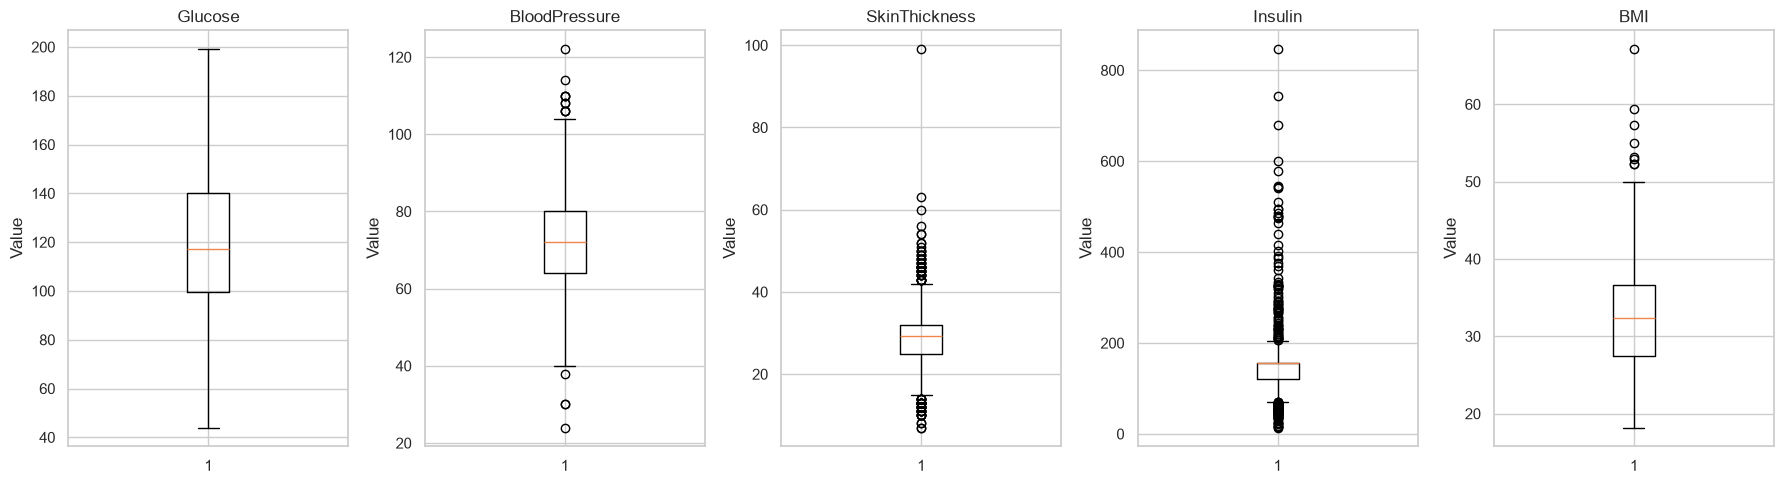

In [32]:
# TODO: Detect outliers in df_mean using the IQR (Interquartile Range) method.
#
# The IQR method defines outliers as values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
# This is the same rule used to draw whiskers in a boxplot.
#
# Steps:
#   1. For each column in SUSPECT_COLS:
#        a. Compute Q1 = 25th percentile and Q3 = 75th percentile.
#        b. Compute IQR = Q3 - Q1.
#        c. Define lower_fence = Q1 - 1.5 * IQR and upper_fence = Q3 + 1.5 * IQR.
#        d. Count outliers: rows where the value < lower_fence or > upper_fence.
#        e. Compute outlier percentage = count / len(df_mean) * 100.
#        f. Append a dict {Feature, Q1, Q3, IQR, Lower fence, Upper fence,
#                          Outlier count, Outlier %} to a list.
#   2. Create a DataFrame and print it rounded to 2 dp.
#   3. Create a boxplot grid: plt.subplots(1, len(SUSPECT_COLS)) showing all five columns.
#      (Boxplots automatically display outliers as individual points.)

# YOUR CODE HERE
outlier_results = []

for col in SUSPECT_COLS:
    # 1a. Compute Q1 and Q3
    Q1 = df_mean[col].quantile(0.25)
    Q3 = df_mean[col].quantile(0.75)

    # 1b. Compute IQR
    IQR = Q3 - Q1

    # 1c. Define fences
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    # 1d. Count outliers
    outliers = df_mean[(df_mean[col] < lower_fence) | (df_mean[col] > upper_fence)]
    outlier_count = len(outliers)

    # 1e. Outlier percentage
    outlier_percent = (outlier_count / len(df_mean)) * 100

    # 1f. Append results
    outlier_results.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower fence': lower_fence,
        'Upper fence': upper_fence,
        'Outlier count': outlier_count,
        'Outlier %': outlier_percent
    })

# 2. Create DataFrame and print rounded table
outlier_df = pd.DataFrame(outlier_results).round(2)
print(outlier_df)

# 3. Create boxplot grid
fig, axes = plt.subplots(1, len(SUSPECT_COLS), figsize=(18, 5))

for_ax = zip(axes, SUSPECT_COLS)
for ax, col in for_ax:
    ax.boxplot(df_mean[col])
    ax.set_title(col)
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()

### Task 9: Feature Engineering & Feature Scaling

Paste your completed Task 9 code and interpretation here.

*Member: __Akshay and fredrick______________*

Features scaled for modeling.
  X_scaled shape: (768, 8)
Ready (zeros replaced by NaN and median-imputed)
New features added: Glucose_Insulin_Ratio, AgeGroup
   Glucose  Insulin  Glucose_Insulin_Ratio  Age AgeGroup
0    148.0    125.0               1.184000   50   Middle
1     85.0    125.0               0.680000   31    Young
2    183.0    125.0               1.464000   32    Young
3     89.0     94.0               0.946809   21    Young
4    137.0    168.0               0.815476   33    Young

Glucose_Insulin_Ratio, mean: 1.068, std: 0.721
BMI_Age_Interaction, mean: 1080.9067708333334 
BMI_Age_Interaction, median: 987.25 
BMI_Age_Interaction, std: 437.8139857381696 


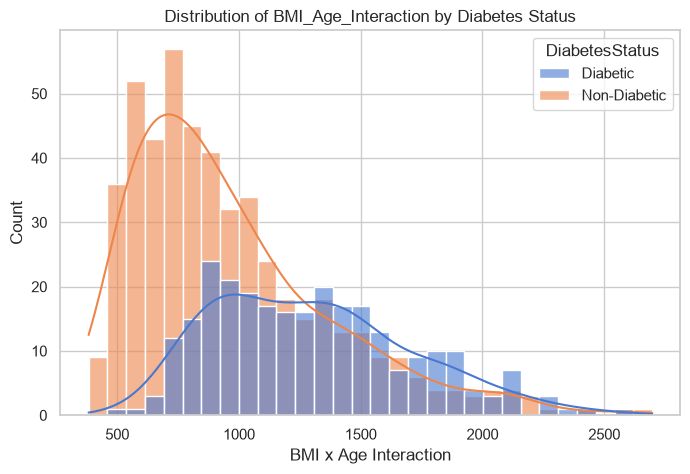

   AgeGroup_Young  AgeGroup_Middle  AgeGroup_Senior
0           False             True            False
1            True            False            False
2            True            False            False


In [33]:
# ── Task 9: Feature Engineering & Feature Scaling ────────────────────────────
# Paste completed code from Module C, Task 9

# Scale features for modeling (standardization)
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print(f"Features scaled for modeling.")
print(f"  X_scaled shape: {X_scaled.shape}")

# ── Task 9 Setup (do not modify) ──────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# StandardScaler: standardisation (z-score) transforms to mean=0, std=1
# MinMaxScaler:   normalisation (min-max)   transforms to range [0, 1]

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df_raw = pd.read_csv(URL)

# Start from a clean dataset: replace impossible zeros with NaN, then median-impute.
# We use median imputation (more robust to skew) as established in Task 8.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df = df_raw.copy()
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)
df[SUSPECT_COLS] = df[SUSPECT_COLS].fillna(df[SUSPECT_COLS].median())

print('Ready (zeros replaced by NaN and median-imputed)')

# Provided: create two medically motivated engineered features

# --- Engineered Feature 1: Glucose-to-Insulin Ratio ---
# In diabetes medicine, the ratio of blood glucose to insulin levels indicates
# insulin resistance, a high ratio suggests the body is producing insulin but
# not responding to it effectively. A ratio is sometimes more informative
# than either value alone.
df['Glucose_Insulin_Ratio'] = df['Glucose'] / df['Insulin']

# --- Engineered Feature 2: Age Group (binning) ---
# Converting a continuous variable into categorical bins can help models capture
# non-linear effects: the risk of Type 2 diabetes increases sharply with age.
# pd.cut() divides Age into three labelled intervals.
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[20, 35, 50, 82],
    labels=['Young', 'Middle', 'Senior'],
    right=True
)

print('New features added: Glucose_Insulin_Ratio, AgeGroup')
print(df[['Glucose', 'Insulin', 'Glucose_Insulin_Ratio', 'Age', 'AgeGroup']].head(5))
print(f'\nGlucose_Insulin_Ratio, mean: {df["Glucose_Insulin_Ratio"].mean():.3f}, '
      f'std: {df["Glucose_Insulin_Ratio"].std():.3f}')

# TODO: Create one more engineered feature and encode the categorical AgeGroup column.
#
# --- Part A: New engineered feature ---
# Create 'BMI_Age_Interaction' = BMI * Age.
# Rationale from the lecture: interaction features capture how two variables
# combine older patients with high BMI may face compounded diabetes risk
# that neither BMI nor Age captures alone.
#
# Steps:
#   1. Compute df['BMI_Age_Interaction'] = df['BMI'] * df['Age'].
#   2. Print the mean, median, and std of the new column.
#   3. Plot a histogram of 'BMI_Age_Interaction' coloured by DiabetesStatus.
#      (First add DiabetesStatus: df['DiabetesStatus'] = df['Outcome'].map({0:'Non-Diabetic',1:'Diabetic'}))
#
# --- Part B: One-hot encode AgeGroup ---
# Machine learning models require numeric inputs, categorical strings must be
# converted. One-hot encoding creates one binary column per category.
# For example: AgeGroup='Young' → AgeGroup_Young=1, AgeGroup_Middle=0, AgeGroup_Senior=0.
#
# Steps:
#   1. Use pd.get_dummies(df['AgeGroup'], prefix='AgeGroup') to create binary columns.
#      Store the result as age_dummies.
#   2. Use pd.concat([df, age_dummies], axis=1) to attach the new columns.
#   3. Drop the original 'AgeGroup' column (it is now redundant).
#   4. Print the column names and the first 3 rows of the new binary columns.

# YOUR CODE HERE
BMI_Age_Interaction = df['BMI'] * df['Age']
print(f'BMI_Age_Interaction, mean: {BMI_Age_Interaction.mean()} ')
print(f'BMI_Age_Interaction, median: {BMI_Age_Interaction.median()} ')
print(f'BMI_Age_Interaction, std: {BMI_Age_Interaction.std()} ')
df["DiabetesStatus"] = df["Outcome"].map({0: "Non-Diabetic",1: "Diabetic"})
plt.figure(figsize=(8, 5))

df['BMI_Age_Interaction'] = BMI_Age_Interaction

# Plot it
sns.histplot(
    data=df,
    x='BMI_Age_Interaction',
    hue='DiabetesStatus',
    bins=30,
    kde=True,
    alpha=0.6
)

plt.title("Distribution of BMI_Age_Interaction by Diabetes Status")
plt.xlabel("BMI x Age Interaction")
plt.ylabel("Count")
plt.show()

age_dummies = pd.get_dummies(df['AgeGroup'], prefix='AgeGroup')
df = pd.concat([df, age_dummies], axis=1)
df.drop(columns=['AgeGroup'], inplace=True)
print(df[['AgeGroup_Young', 'AgeGroup_Middle', 'AgeGroup_Senior']].head(3))



--- Scaling Comparison ---
                          Raw mean  Raw std  Std mean  Std std  MinMax min  \
Pregnancies                  3.845    3.370      -0.0    1.001         0.0   
Glucose                    121.656   30.438       0.0    1.001         0.0   
BloodPressure               72.387   12.097       0.0    1.001         0.0   
SkinThickness               29.108    8.791      -0.0    1.001         0.0   
Insulin                    140.672   86.383       0.0    1.001         0.0   
BMI                         32.455    6.875       0.0    1.001         0.0   
DiabetesPedigreeFunction     0.472    0.331       0.0    1.001         0.0   
Age                         33.241   11.760       0.0    1.001         0.0   
Glucose_Insulin_Ratio        1.068    0.721       0.0    1.001         0.0   
BMI_Age_Interaction       1080.907  437.814      -0.0    1.001         0.0   

                          MinMax max  
Pregnancies                      1.0  
Glucose                          1.0

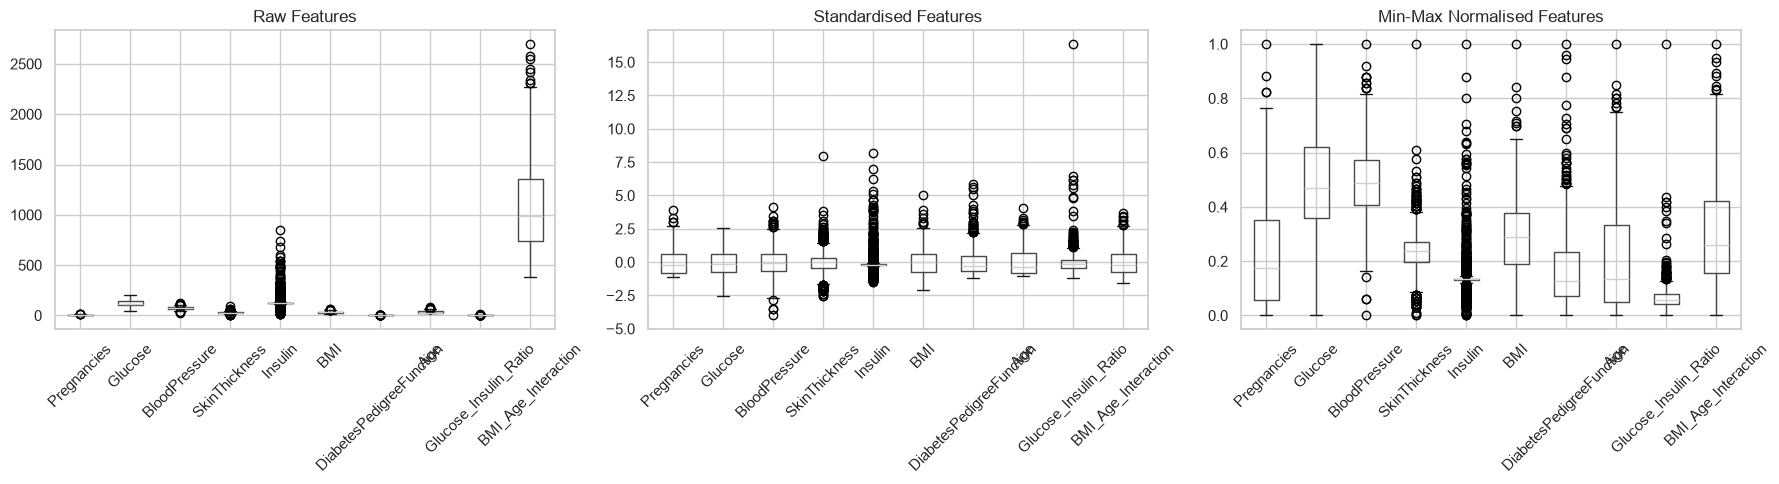

In [34]:
# TODO: Apply Standardisation and Normalisation to the numeric features.
#
# Why scale?
# Features like Insulin (range 0–846) and BloodPressure (range 24–122) are on
# completely different scales. Distance-based models (like KNN) and gradient-based
# optimisers will be dominated by large-scale features unless we normalise.
#
# Standardisation (z-score):  z = (x - mean) / std   → result has mean=0, std=1
#                              Best when data is approximately Normal.
# Normalisation (min-max):     x' = (x - min) / (max - min)  → result in [0, 1]
#                              Best when the range is bounded and known.
#
# Steps:
#   1. Define SCALE_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
#                            'Insulin','BMI','DiabetesPedigreeFunction','Age',
#                            'Glucose_Insulin_Ratio','BMI_Age_Interaction']
#      (Use the clean df with engineered features from above; drop AgeGroup binary cols.)
#
#   2. Apply StandardScaler:
#        scaler_std = StandardScaler()
#        X_std = pd.DataFrame(scaler_std.fit_transform(df[SCALE_COLS]),
#                             columns=SCALE_COLS)
#
#   3. Apply MinMaxScaler similarly → X_minmax.
#
#   4. Print a comparison table:
#      Column | Raw mean | Raw std | Std mean | Std std | MinMax min | MinMax max
#      Round all to 3 dp.
#
#   5. Create a 3-panel figure (plt.subplots(1, 3, figsize=(15, 4))):
#      Panel 1: Boxplot of raw features for SCALE_COLS.
#      Panel 2: Boxplot of X_std.
#      Panel 3: Boxplot of X_minmax.
#      Each panel should show all feature columns on the x-axis.
#      (Use df[SCALE_COLS].boxplot(ax=axes[0], rot=45))

# YOUR CODE HERE

# Step 1: Define columns to scale
SCALE_COLS = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Glucose_Insulin_Ratio',
    'BMI_Age_Interaction'
]

# Step 2: Apply Standardisation (Z-score)
scaler_std = StandardScaler()

X_std = pd.DataFrame(
    scaler_std.fit_transform(df[SCALE_COLS]),
    columns=SCALE_COLS
)

# Step 3: Apply Min-Max Normalisation
scaler_mm = MinMaxScaler()

X_minmax = pd.DataFrame(
    scaler_mm.fit_transform(df[SCALE_COLS]),
    columns=SCALE_COLS
)

# Step 4: Create comparison table
comparison = pd.DataFrame({
    'Raw mean': df[SCALE_COLS].mean(),
    'Raw std': df[SCALE_COLS].std(),
    'Std mean': X_std.mean(),
    'Std std': X_std.std(),
    'MinMax min': X_minmax.min(),
    'MinMax max': X_minmax.max()
})

print('--- Scaling Comparison ---')
print(comparison.round(3))

# Step 5: Visualise the effect of scaling
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Raw data
df[SCALE_COLS].boxplot(ax=axes[0], rot=45)
axes[0].set_title('Raw Features')

# Standardised data
X_std.boxplot(ax=axes[1], rot=45)
axes[1].set_title('Standardised Features')

# Normalised data
X_minmax.boxplot(ax=axes[2], rot=45)
axes[2].set_title('Min-Max Normalised Features')

plt.tight_layout()
plt.show()


---
## Section D: Feature Selection, Regression & Model Evaluation
*Source: Module D (Week 2, Day 2)*

**Module Lead:** [Insert Module D member name]

Paste your completed **Tasks 10, 11, and 12** code cells and interpretation answers here.

### Task 10: Feature Selection & Train / Test Split

Paste your completed Task 10 code and interpretation here.

**Module D note:** your module notebook's Setup cell for this task starts with `df_raw = pd.read_csv(...)` followed by `df = df_raw.copy()` and its own zero-cleaning step. Delete those lines before pasting. The shared `df` from the top of this notebook is already cleaned and includes `DiabetesStatus` and `AgeGroup`. Keep only the median imputation line, applied directly to the existing `df`:

```python
df[SUSPECT_COLS] = df[SUSPECT_COLS].fillna(df[SUSPECT_COLS].median())
```

*Member: Hrithik Wadile

In [35]:
# ── Task 10 Setup (do not modify) ─────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# sklearn: the standard Python machine learning library
from sklearn.linear_model import LinearRegression  # OLS linear regression
from sklearn.feature_selection import RFE          # Recursive Feature Elimination (wrapper method)
from sklearn.model_selection import train_test_split  # splits data into train and test sets
from sklearn.preprocessing import StandardScaler      # z-score standardisation

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df_raw = pd.read_csv(URL)

# Apply the same cleaning pipeline established in Module C:
# Replace impossible zeros → NaN → median imputation.
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df = df_raw.copy()
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)
df[SUSPECT_COLS] = df[SUSPECT_COLS].fillna(df[SUSPECT_COLS].median())

FEATURE_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
                'Insulin','BMI','DiabetesPedigreeFunction','Age']

X = df[FEATURE_COLS]   # all 8 features, shape (768, 8)
y = df['Outcome']      # binary target, shape (768,)

print('Ready')


Ready


--- Filter Method: Pearson |r| with Outcome ---
                          |r| with Outcome   p-value
Glucose                             0.4928  0.000000
BMI                                 0.3120  0.000000
Age                                 0.2384  0.000000
Pregnancies                         0.2219  0.000000
SkinThickness                       0.2149  0.000000
Insulin                             0.2038  0.000000
DiabetesPedigreeFunction            0.1738  0.000001
BloodPressure                       0.1657  0.000004

Top 4 features by Pearson |r|: ['Glucose', 'BMI', 'Age', 'Pregnancies']


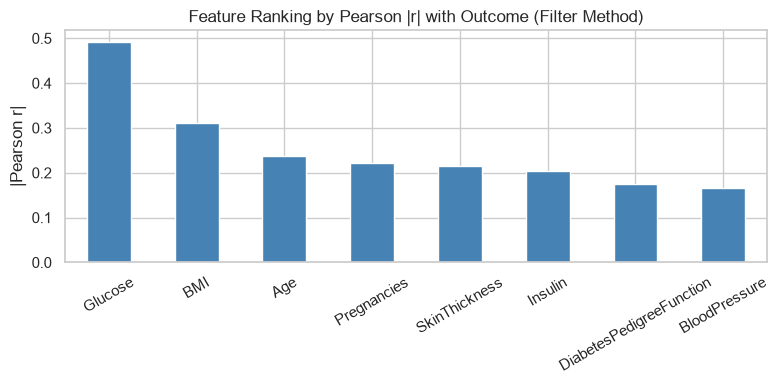

In [36]:
# Provided: Filter method: rank features by Pearson |r| with the target

# --- Filter Method: Pearson Correlation ---
# Filter methods select features using statistical relationships computed BEFORE
# model training: they are fast and model-agnostic.
# Here we rank every feature by its absolute Pearson correlation with Outcome.
# Features with |r| closer to 1 have a stronger linear relationship with the target.

corr_scores = {}
for col in FEATURE_COLS:
    # stats.pearsonr returns (r, p_value); we only need |r| for ranking here.
    r, p = stats.pearsonr(X[col], y)
    corr_scores[col] = {'|r| with Outcome': round(abs(r), 4), 'p-value': round(p, 6)}

corr_df = pd.DataFrame(corr_scores).T.sort_values('|r| with Outcome', ascending=False)

print('--- Filter Method: Pearson |r| with Outcome ---')
print(corr_df.to_string())

# Select the top 4 features by |r|: a common heuristic for this dataset size.
TOP_4 = corr_df.head(4).index.tolist()
print(f'\nTop 4 features by Pearson |r|: {TOP_4}')

# Visualise as a bar chart so the ranking is immediately clear.
fig, ax = plt.subplots(figsize=(8, 4))
corr_df['|r| with Outcome'].plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Feature Ranking by Pearson |r| with Outcome (Filter Method)')
ax.set_ylabel('|Pearson r|')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()


In [37]:
# Provided: Wrapper method: Recursive Feature Elimination (RFE)
#
# RFE is called a 'wrapper' method because it WRAPS a machine learning model
# inside the feature selection loop. It uses the model's own sense of feature
# importance, not a generic statistic like Pearson r.
#
# How RFE works (from the lecture, slide on Wrapper Methods):
#   Step 1  Start with all features.
#   Step 2  Train the model on the full feature set.
#   Step 3  Rank features by importance (for LinearRegression: by |coefficient|).
#   Step 4  Remove the LEAST important feature.
#   Step 5  Retrain the model and repeat until n_features_to_select remain.

from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Step 1: Scale features BEFORE RFE.
# RFE ranks by |coefficient|. If Insulin (range 0–800) is not scaled,
# its coefficient will be tiny just because of its large scale, not
# because it is unimportant. Scaling levels the playing field.
scaler_rfe = StandardScaler()
X_scaled   = scaler_rfe.fit_transform(X)   # fit on ALL data for feature selection only
# Note: we fit on all data here because RFE is for selection, not evaluation.
# The train/test split (for honest evaluation) comes in the next cell.


# Step 2: Create the RFE object.
# estimator = the model used to judge feature importance.
# n_features_to_select = how many features to keep.
# step = how many features to remove per iteration (1 = slowest but most precise).
estimator = LinearRegression()
rfe       = RFE(estimator=estimator, n_features_to_select=4, step=1)

# Step 3: Fit RFE, this runs the full elimination loop internally.
rfe.fit(X_scaled, y)

# Step 4: Inspect results.
# rfe.ranking_ gives each feature a rank: rank=1 means SELECTED; higher = eliminated earlier.
# rfe.support_ gives True for selected features, False for eliminated ones.
rfe_results = pd.DataFrame({
    'Feature':   FEATURE_COLS,
    'RFE Rank':  rfe.ranking_,
    'Selected?': rfe.support_
}).sort_values('RFE Rank')

print('--- Wrapper Method: Recursive Feature Elimination (RFE) ---')
print(f'Target: keep the top {rfe.n_features_to_select} features out of {len(FEATURE_COLS)}')
print()
print(rfe_results.to_string(index=False))

RFE_TOP4 = rfe_results[rfe_results['Selected?']]['Feature'].tolist()
print(f'\nRFE selected features: {RFE_TOP4}')

# Step 5: Compare Pearson filter vs RFE wrapper.
print(f'\nPearson top-4 : {TOP_4}')
print(f'RFE top-4     : {RFE_TOP4}')
agreed = set(TOP_4) == set(RFE_TOP4)
print(f'Agreement     : {"Both methods agree" if agreed else " Methods disagree: see Interpretation cell"}')


--- Wrapper Method: Recursive Feature Elimination (RFE) ---
Target: keep the top 4 features out of 8

                 Feature  RFE Rank  Selected?
             Pregnancies         1       True
                 Glucose         1       True
DiabetesPedigreeFunction         1       True
                     BMI         1       True
                     Age         2      False
           BloodPressure         3      False
                 Insulin         4      False
           SkinThickness         5      False

RFE selected features: ['Pregnancies', 'Glucose', 'DiabetesPedigreeFunction', 'BMI']

Pearson top-4 : ['Glucose', 'BMI', 'Age', 'Pregnancies']
RFE top-4     : ['Pregnancies', 'Glucose', 'DiabetesPedigreeFunction', 'BMI']
Agreement     :  Methods disagree: see Interpretation cell


In [38]:
# Provided: Wrapper method: Forward Feature Selection
#
# Forward selection is the OPPOSITE of RFE:
# it starts with NO features and adds the most useful one at a time.
# From the lecture (Week 2 Day 2 slides):
#   Step 1 Start with an empty feature set.
#   Step 2 Test each remaining feature individually.
#   Step 3 Add the feature that improves model score the most.
#   Step 4 Repeat until n_features_to_select features have been added.
#
# sklearn provides SequentialFeatureSelector for this purpose.

from sklearn.feature_selection import SequentialFeatureSelector

# SequentialFeatureSelector with direction='forward' = forward selection.
# cv=5: uses 5-fold cross-validation to score each candidate feature set.
# scoring='r2': the feature that maximises R² is added at each step.
sfs = SequentialFeatureSelector(
    estimator=LinearRegression(),
    n_features_to_select=4,
    direction='forward',    # 'forward' adds features; 'backward' removes (= greedy RFE)
    scoring='r2',
    cv=5
)

# We pass X (unscaled), SequentialFeatureSelector uses CV internally,
# so scaling would need to be inside a Pipeline for strict correctness.
# For feature selection comparison purposes, this is sufficient.
sfs.fit(X, y)

# .get_support() returns a boolean mask aligned with FEATURE_COLS.
sfs_mask = sfs.get_support()
SFS_TOP4 = [feat for feat, sel in zip(FEATURE_COLS, sfs_mask) if sel]

print('--- Wrapper Method: Forward Feature Selection ---')
sfs_results = pd.DataFrame({'Feature': FEATURE_COLS, 'Selected?': sfs_mask})
print(sfs_results.to_string(index=False))
print(f'\nForward selection chose: {SFS_TOP4}')

# Summary across all three filter/wrapper approaches so far.
print('\n=== Feature Selection Summary ===')
print(f'Pearson |r|       : {TOP_4}')
print(f'RFE (backward)    : {RFE_TOP4}')
print(f'Forward selection : {SFS_TOP4}')


--- Wrapper Method: Forward Feature Selection ---
                 Feature  Selected?
             Pregnancies       True
                 Glucose       True
           BloodPressure      False
           SkinThickness      False
                 Insulin      False
                     BMI       True
DiabetesPedigreeFunction       True
                     Age      False

Forward selection chose: ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']

=== Feature Selection Summary ===
Pearson |r|       : ['Glucose', 'BMI', 'Age', 'Pregnancies']
RFE (backward)    : ['Pregnancies', 'Glucose', 'DiabetesPedigreeFunction', 'BMI']
Forward selection : ['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction']


In [39]:
# Provided: Embedded method Lasso Regression (L1 regularisation)
#
# Embedded methods perform feature selection DURING model training.
# From the lecture (Week 2 Day 2):
#   - Lasso (L1): adds a penalty = α × Σ|βⱼ| to the loss.
#     Features with low predictive value get their coefficient shrunk to EXACTLY zero.
#     Coefficient = 0 means the feature is effectively removed from the model.
#   - Ridge (L2): adds a penalty = α × Σβⱼ². Shrinks coefficients toward zero
#     but never to exactly zero, Ridge does NOT perform feature selection.
#
# This is why Lasso is the standard embedded feature selection tool:
# it selects features and fits the model in one step.

from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline

# We use a Pipeline to chain scaling and Lasso prevents data leakage.
# alpha (λ in the lecture notation) controls regularisation strength:
#   α = 0   → plain OLS (no penalty, no selection)
#   α large → all coefficients driven to zero (too aggressive)
# We try three values to show the effect.

print('--- Embedded Method: Lasso (L1) Feature Selection ---')
print(f'{"Alpha (λ)":<12}', end='')
for feat in FEATURE_COLS:
    print(f'{feat[:10]:<12}', end='')
print('Features kept')
print('-' * (12 + 12*len(FEATURE_COLS) + 14))

for alpha in [0.01, 0.1, 1.0]:
    lasso_pipe = Pipeline([
        ('scaler', StandardScaler()),    # fit scaler on training data (X here for selection)
        ('lasso',  Lasso(alpha=alpha, max_iter=5000))
    ])
    lasso_pipe.fit(X, y)

    coefs  = lasso_pipe.named_steps['lasso'].coef_
    # A coefficient is 'zeroed out' if its absolute value is below a tiny threshold.
    # Floating point arithmetic rarely gives exactly 0.0, so we use 1e-6 as a threshold.
    kept   = (np.abs(coefs) > 1e-6).sum()
    print(f'{alpha:<12}', end='')
    for c in coefs:
        marker = f'{c:.3f}' if abs(c) > 1e-6 else '  ZERO  '
        print(f'{marker:<12}', end='')
    print(f'{kept}/{len(FEATURE_COLS)}')

print()
print('Observation: as alpha increases, Lasso zeros out more coefficients.')
print('Features zeroed at alpha=0.1 are the ones Lasso considers least useful.')
print('Compare these eliminated features with the Pearson and RFE rankings above.')


--- Embedded Method: Lasso (L1) Feature Selection ---
Alpha (λ)   Pregnancie  Glucose     BloodPress  SkinThickn  Insulin     BMI         DiabetesPe  Age         Features kept
--------------------------------------------------------------------------------------------------------------------------
0.01        0.062       0.187         ZERO        ZERO        ZERO      0.088       0.035       0.016       5/8
0.1           ZERO      0.131         ZERO        ZERO        ZERO      0.019         ZERO        ZERO      2/8
1.0           ZERO        ZERO        ZERO        ZERO        ZERO        ZERO        ZERO        ZERO      0/8

Observation: as alpha increases, Lasso zeros out more coefficients.
Features zeroed at alpha=0.1 are the ones Lasso considers least useful.
Compare these eliminated features with the Pearson and RFE rankings above.


In [40]:
# ── Task 10: Feature Selection & Train / Test Split ──────────────────────────
# Paste completed code from Module D, Task 10

# Placeholder: Feature Selection Results
# Replace with your actual selected features from RFE, Pearson, or ANOVA
# TODO: Build a feature selection comparison table across all three method families.
#
# You have now seen:
#   - Filter  : Pearson |r| → ranked by TOP_4
#   - Wrapper : RFE → ranked by RFE_TOP4, Forward selection → SFS_TOP4
#   - Embedded: Lasso → features zeroed at alpha=0.1
#
# Steps:
#   1. For each of the 8 FEATURE_COLS, create a row with:
#        'Feature' | 'Pearson |r|' | 'Pearson selected?' | 'RFE rank' |
#        'RFE selected?' | 'SFS selected?' | 'Lasso coef (α=0.1)' | 'Lasso selected?'
#
#   2. To get the Lasso coefficients at alpha=0.1, re-fit once:
#        lasso_01 = Pipeline([('sc', StandardScaler()), ('m', Lasso(alpha=0.1, max_iter=5000))])
#        lasso_01.fit(X, y)
#        lasso_coefs = lasso_01.named_steps['m'].coef_
#
#   3. Sort the table by Pearson |r| descending.
#   4. Print the full table.
#   5. Count how many features ALL three method families agree on as 'selected'.
#      Print: 'All three methods agree on N features: [...]'

# YOUR CODE HERE
# --- Feature selection comparison table across all three method families ---
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline

# Step 2: re-fit Lasso once at alpha=0.1 to grab its coefficients
lasso_01 = Pipeline([('sc', StandardScaler()), ('m', Lasso(alpha=0.1, max_iter=5000))])
lasso_01.fit(X, y)
lasso_coefs = lasso_01.named_steps['m'].coef_
lasso_selected = np.abs(lasso_coefs) > 1e-6        # nonzero coefficient = kept by Lasso

# Per-feature lookups from the results the provided cells already computed
rfe_rank_map     = dict(zip(FEATURE_COLS, rfe.ranking_))
rfe_selected_map = dict(zip(FEATURE_COLS, rfe.support_))
sfs_selected_map = dict(zip(FEATURE_COLS, sfs_mask))
lasso_coef_map   = dict(zip(FEATURE_COLS, lasso_coefs))
lasso_sel_map    = dict(zip(FEATURE_COLS, lasso_selected))

# Step 1: build one row per feature
rows = []
for col in FEATURE_COLS:
    rows.append({
        'Feature':            col,
        'Pearson |r|':        corr_df.loc[col, '|r| with Outcome'],
        'Pearson selected?':  col in TOP_4,
        'RFE rank':           rfe_rank_map[col],
        'RFE selected?':      rfe_selected_map[col],
        'SFS selected?':      sfs_selected_map[col],
        'Lasso coef (α=0.1)': round(lasso_coef_map[col], 4),
        'Lasso selected?':    bool(lasso_sel_map[col]),
    })

# Step 3 & 4: sort by Pearson |r| descending and print
comparison_df = pd.DataFrame(rows).sort_values('Pearson |r|', ascending=False)
print('--- Feature Selection Comparison Across Method Families ---')
print(comparison_df.to_string(index=False))

# Step 5: features that ALL THREE FAMILIES agree on
#   Filter = Pearson (TOP_4) | Wrapper = RFE | Embedded = Lasso
print()
agree_all = [
    col for col in FEATURE_COLS
    if (col in TOP_4) and rfe_selected_map[col] and bool(lasso_sel_map[col])
]
print(f'\nAll three methods agree on {len(agree_all)} features: {agree_all}')

--- Feature Selection Comparison Across Method Families ---
                 Feature  Pearson |r|  Pearson selected?  RFE rank  RFE selected?  SFS selected?  Lasso coef (α=0.1)  Lasso selected?
                 Glucose       0.4928               True         1           True           True              0.1306             True
                     BMI       0.3120               True         1           True           True              0.0186             True
                     Age       0.2384               True         2          False          False              0.0000            False
             Pregnancies       0.2219               True         1           True           True              0.0000            False
           SkinThickness       0.2149              False         5          False          False              0.0000            False
                 Insulin       0.2038              False         4          False          False              0.0000            False
Di

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Step 3: report shapes and class balance
print('Shapes')
print(f'  X_train: {X_train.shape}')
print(f'  X_test : {X_test.shape}')
print('\nOutcome class ratio (proportion diabetic)')
print(f'  y_train: {y_train.mean():.3f}')
print(f'  y_test : {y_test.mean():.3f}   (stratify=y keeps these close)')

# Step 4: fit scaler on TRAIN ONLY, then transform both sets
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURE_COLS, index=X_train.index)
X_test_sc  = pd.DataFrame(scaler.transform(X_test),      columns=FEATURE_COLS, index=X_test.index)

# Step 5: train means should all be ~0 after standardisation
print('\nMean of each column in X_train_sc (should be ~0):')
print(X_train_sc.mean().round(6).to_string())

Shapes
  X_train: (614, 8)
  X_test : (154, 8)

Outcome class ratio (proportion diabetic)
  y_train: 0.349
  y_test : 0.351   (stratify=y keeps these close)

Mean of each column in X_train_sc (should be ~0):
Pregnancies                -0.0
Glucose                    -0.0
BloodPressure               0.0
SkinThickness              -0.0
Insulin                    -0.0
BMI                        -0.0
DiabetesPedigreeFunction   -0.0
Age                        -0.0


In [42]:
# Provided: K-Fold Cross-Validation, a more robust alternative to a single train/test split
#
# From the lecture (Week 2 Day 2, 'Methods for Model Evaluation'):
#   Train-Test Split → one split, fast, but the result depends on which rows
#                       happened to land in the test set (luck of the draw).
#   K-Fold CV        → the data is split into k folds; the model is trained and
#                       tested k times, each fold gets a turn as the test set.
#                       Results are averaged → a more stable, less luck-dependent estimate.
#                       Common choices: k = 5 or k = 10 (we use k = 5 here).
#
# We evaluate the SAME Linear Regression / REG_FEATURES setup used in Task 11,
# so the comparison between a single split and K-Fold CV is apples-to-apples.

from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

REG_FEATURES_CV = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                    'Insulin', 'DiabetesPedigreeFunction', 'Age']
X_cv = df[REG_FEATURES_CV]
y_cv = df['BMI']

kf = KFold(n_splits=5, shuffle=True, random_state=42)  # same RANDOM_STATE=42 as everywhere else

cv_r2_scores = cross_val_score(LinearRegression(), X_cv, y_cv, cv=kf, scoring='r2')

print('--- 5-Fold Cross-Validation: Linear Regression predicting BMI ---')
print(f'R² per fold : {np.round(cv_r2_scores, 3)}')
print(f'Mean R²     : {cv_r2_scores.mean():.3f}')
print(f'Std  R²     : {cv_r2_scores.std():.3f}  (spread across folds = how lucky/unlucky a single split could be)')
print()
print('Compare this Mean R² (and its spread) to the single train/test split R² you will compute in Task 11.')
print('A single split gives ONE number; K-Fold CV gives a DISTRIBUTION, which is the more honest picture.')


--- 5-Fold Cross-Validation: Linear Regression predicting BMI ---
R² per fold : [0.205 0.386 0.408 0.357 0.302]
Mean R²     : 0.332
Std  R²     : 0.073  (spread across folds = how lucky/unlucky a single split could be)

Compare this Mean R² (and its spread) to the single train/test split R² you will compute in Task 11.
A single split gives ONE number; K-Fold CV gives a DISTRIBUTION, which is the more honest picture.


### Task 11: Linear Regression (Fitting & Interpreting Coefficients)

Paste your completed Task 11 code and interpretation here.

*Member: Sahil Suryawanshi

In [43]:
# ── Task 11 Setup (do not modify) ─────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df_raw = pd.read_csv(URL)
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df = df_raw.copy()
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)
df[SUSPECT_COLS] = df[SUSPECT_COLS].fillna(df[SUSPECT_COLS].median())

# Regression target: BMI (continuous, this is a regression task).
# Predictors: all other clinical features except Outcome and BMI itself.
REG_FEATURES = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'DiabetesPedigreeFunction', 'Age']
REG_TARGET   = 'BMI'

X_reg = df[REG_FEATURES]
y_reg = df[REG_TARGET]

# Same 80/20 split as Task 10 (same random_state=42 for reproducibility across modules).
X_tr, X_te, y_tr, y_te = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f'Train: {len(X_tr)} rows  |  Test: {len(X_te)} rows')
print('Ready')


Train: 614 rows  |  Test: 154 rows
Ready


Intercept  β₀ = 25.9633
Slope      β₁ = 0.0524
Equation   : BMI = 25.96 + 0.0524 × Glucose

--- Simple LR Test-Set Performance ---
MAE  = 5.1095  (average absolute error in BMI units)
RMSE = 6.4319  (root mean squared error, penalises large errors more)
R²   = 0.0542  (fraction of BMI variance explained by Glucose alone)


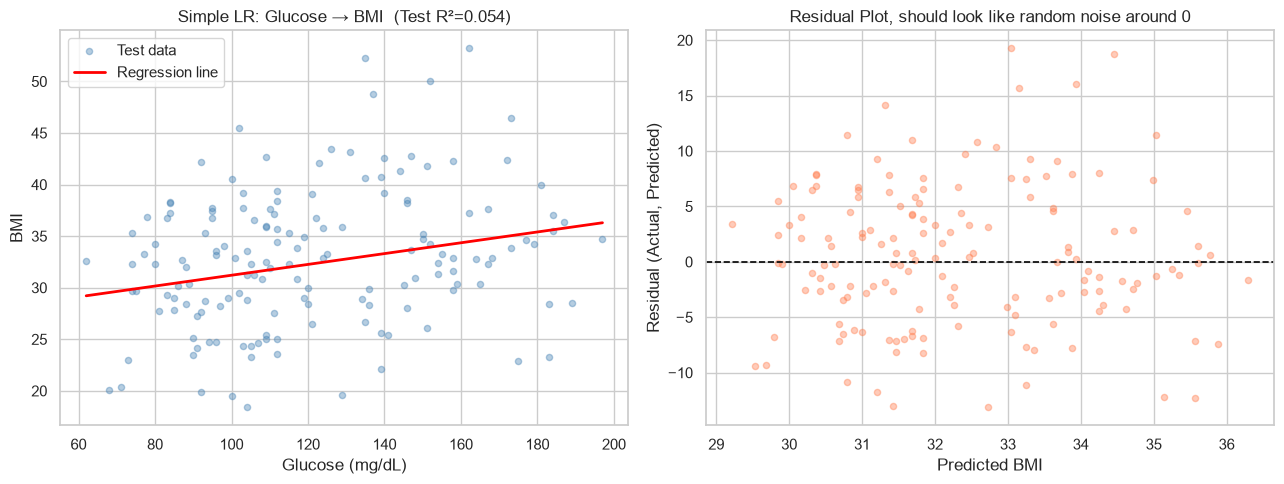

In [44]:
# Provided: Simple Linear Regression, predict BMI from Glucose only

# --- Why Simple LR first? ---
# Starting with one predictor makes the model completely visualisable (scatter + line).
# It also establishes a baseline: if Multiple LR barely improves over Simple LR,
# the extra features are not contributing much.

# sklearn requires X to be 2-D, double brackets [[...]] give shape (n, 1) instead of (n,).
X_tr_slr = X_tr[['Glucose']]   # train set, one column
X_te_slr = X_te[['Glucose']]   # test set, one column

slr = LinearRegression()          # create the model object
slr.fit(X_tr_slr, y_tr)          # fit ONLY on the training set

# intercept_ = β₀: predicted BMI when Glucose = 0 (algebraically necessary; not clinically meaningful here)
# coef_[0]   = β₁: expected change in BMI per 1 mg/dL increase in Glucose
print(f'Intercept  β₀ = {slr.intercept_:.4f}')
print(f'Slope      β₁ = {slr.coef_[0]:.4f}')
print(f'Equation   : BMI = {slr.intercept_:.2f} + {slr.coef_[0]:.4f} × Glucose')
print()

# Evaluate on the TEST set, this is the honest performance estimate.
y_pred_slr = slr.predict(X_te_slr)
mae  = mean_absolute_error(y_te, y_pred_slr)
rmse = np.sqrt(mean_squared_error(y_te, y_pred_slr))
r2   = r2_score(y_te, y_pred_slr)
print(f'--- Simple LR Test-Set Performance ---')
print(f'MAE  = {mae:.4f}  (average absolute error in BMI units)')
print(f'RMSE = {rmse:.4f}  (root mean squared error, penalises large errors more)')
print(f'R²   = {r2:.4f}  (fraction of BMI variance explained by Glucose alone)')

# --- Visualise: scatter + regression line + residuals ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: scatter plot with the fitted line.
axes[0].scatter(X_te_slr, y_te, alpha=0.4, s=20, color='steelblue', label='Test data')
x_line = np.linspace(X_te_slr.min().values[0], X_te_slr.max().values[0], 200).reshape(-1,1)
axes[0].plot(x_line, slr.predict(x_line), color='red', linewidth=2, label='Regression line')
axes[0].set_xlabel('Glucose (mg/dL)')
axes[0].set_ylabel('BMI')
axes[0].set_title(f'Simple LR: Glucose → BMI  (Test R²={r2:.3f})')
axes[0].legend()

# Right: residual plot, residuals vs predicted values.
# A good model has residuals randomly scattered around 0 with no visible pattern.
# Patterns (curved, funnel-shaped) suggest model misspecification or unequal variance.
residuals = y_te.values - y_pred_slr
axes[1].scatter(y_pred_slr, residuals, alpha=0.4, s=20, color='coral')
axes[1].axhline(0, color='black', linewidth=1.2, linestyle='--')
axes[1].set_xlabel('Predicted BMI')
axes[1].set_ylabel('Residual (Actual, Predicted)')
axes[1].set_title('Residual Plot, should look like random noise around 0')

plt.tight_layout()
plt.show()


Linear Regression Model Fitted.

Model Coefficients:
  Pregnancies: 0.0187
  Glucose: 0.0069
  BloodPressure: -0.0003
  SkinThickness: -0.0001
  Insulin: -0.0001
  BMI: 0.0156
  DiabetesPedigreeFunction: 0.1136
  Age: 0.0017
MULTIPLE LINEAR REGRESSION (SORTED BY COEFFICIENT)
                 Feature  Coefficient
DiabetesPedigreeFunction     1.626967
           SkinThickness     0.424355
           BloodPressure     0.108800
                     Age    -0.089041
                 Glucose     0.029549
             Pregnancies    -0.006719
                 Insulin     0.003962

Intercept = 10.3451


MULTIPLE LINEAR REGRESSION TEST PERFORMANCE
MAE = 4.3867
RMSE = 5.8982
R² = 0.2046


COMPARING THE VALUES TO THE SIMPLE LINEAR REGRESSION MODEL
MAE of SLR  = 5.1095 vs MAE of MLR = 4.3867
RMSE of SLR = 6.4319 vs RMSE of MLR = 5.8982
R² of SLR = 0.0542  vs R² of MLR = 0.2046


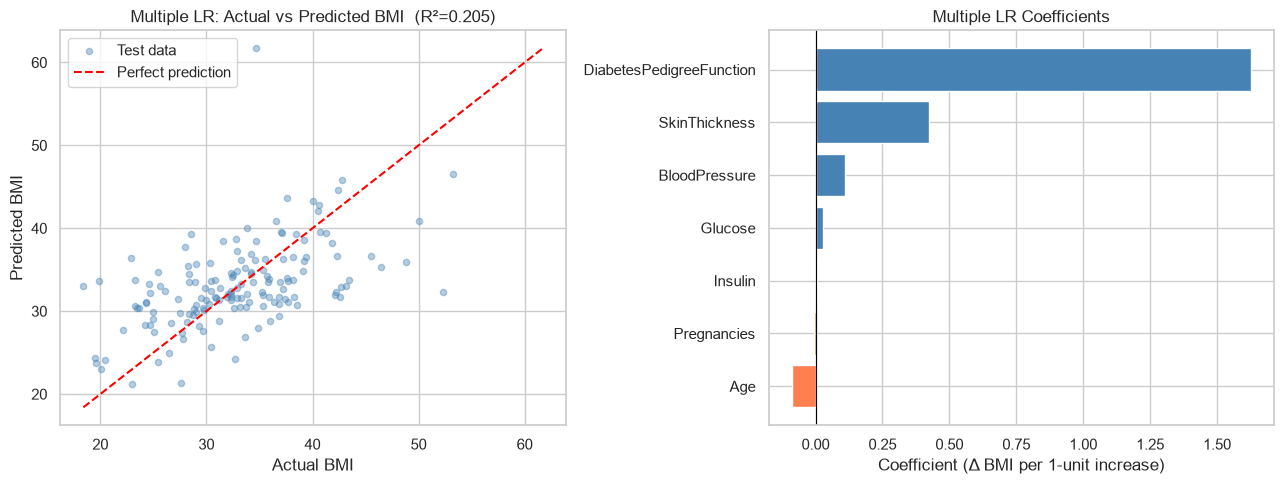

In [45]:
# ── Task 11: Linear Regression (Fitting & Interpreting Coefficients) ───────
# Paste completed code from Module D, Task 11

# Fit Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Linear Regression Model Fitted.")
print(f"\nModel Coefficients:")
for feature, coef in zip(X_train.columns, model.coef_):
    print(f"  {feature}: {coef:.4f}")

mlr = LinearRegression()
mlr.fit(X_tr, y_tr)
coef_table = pd.DataFrame({
    'Feature': REG_FEATURES,
    'Coefficient': mlr.coef_
})
coef_table['abs'] = coef_table['Coefficient'].abs()
coef_table = coef_table.sort_values('abs', ascending=False).drop(columns='abs')

print("MULTIPLE LINEAR REGRESSION (SORTED BY COEFFICIENT)")
print(coef_table.to_string(index=False))
print(f'\nIntercept = {mlr.intercept_:.4f}')

y_pred_mlr = mlr.predict(X_te)
mae_mlr  = mean_absolute_error(y_te, y_pred_mlr)
rmse_mlr = np.sqrt(mean_squared_error(y_te, y_pred_mlr))
r2_mlr   = r2_score(y_te, y_pred_mlr)
print("\n")
print(f"MULTIPLE LINEAR REGRESSION TEST PERFORMANCE")
print(f"MAE = {mae_mlr:.4f}")
print(f"RMSE = {rmse_mlr:.4f}")
print(f"R² = {r2_mlr:.4f}")
print("\n")
print("COMPARING THE VALUES TO THE SIMPLE LINEAR REGRESSION MODEL")
print(f'MAE of SLR  = {mae:.4f} vs MAE of MLR = {mae_mlr:.4f}')
print(f'RMSE of SLR = {rmse:.4f} vs RMSE of MLR = {rmse_mlr:.4f}')
print(f'R² of SLR = {r2:.4f}  vs R² of MLR = {r2_mlr:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_te, y_pred_mlr, alpha=0.4, s=20, color='steelblue', label='Test data')
lims = [min(y_te.min(), y_pred_mlr.min()), max(y_te.max(), y_pred_mlr.max())]
axes[0].plot(lims, lims, color='red', linestyle='--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual BMI')
axes[0].set_ylabel('Predicted BMI')
axes[0].set_title(f'Multiple LR: Actual vs Predicted BMI  (R²={r2_mlr:.3f})')
axes[0].legend()

coef_plot = coef_table.sort_values('Coefficient')
colors = ['coral' if c < 0 else 'steelblue' for c in coef_plot['Coefficient']]
axes[1].barh(coef_plot['Feature'], coef_plot['Coefficient'], color=colors, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('Coefficient (Δ BMI per 1-unit increase)')
axes[1].set_title('Multiple LR Coefficients')

plt.tight_layout()
plt.show()

### Task 12: Model Evaluation & Residual Analysis

Paste your completed Task 12 code and interpretation here.

*Member: ________________*

In [46]:
# ── Task 12 Setup (do not modify) ─────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
# Pipeline chains preprocessing steps and a model into one object.
# This prevents data leakage: the polynomial transformer is fitted only on
# the training fold, not on the full dataset.
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 4)

URL = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df_raw = pd.read_csv(URL)
SUSPECT_COLS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df = df_raw.copy()
df[SUSPECT_COLS] = df[SUSPECT_COLS].replace(0, np.nan)
df[SUSPECT_COLS] = df[SUSPECT_COLS].fillna(df[SUSPECT_COLS].median())

# Use only Glucose (one feature) so we can visualise the fit in 2-D.
# With two features we would need a 3-D plot, much harder to interpret.
X_1d = df[['Glucose']]
y_1d = df['BMI']

X_tr_1d, X_te_1d, y_tr_1d, y_te_1d = train_test_split(
    X_1d, y_1d, test_size=0.20, random_state=42
)

print(f'Train: {len(X_tr_1d)} rows  |  Test: {len(X_te_1d)} rows')
print('Ready')


Train: 614 rows  |  Test: 154 rows
Ready


In [47]:
# Provided: compute all four evaluation metrics and explain each one

# Fit a simple linear model (degree=1) our baseline for the comparison.
lin_model = LinearRegression()
lin_model.fit(X_tr_1d, y_tr_1d)
y_pred_lin = lin_model.predict(X_te_1d)

# --- Metric 1: MAE (Mean Absolute Error) ---
# Average of |actual - predicted| across all test rows.
# Interpretation: on average, our prediction is off by MAE BMI units.
# Advantage: same units as the target; easy to explain to non-technical audiences.
mae  = mean_absolute_error(y_te_1d, y_pred_lin)

# --- Metric 2: MSE (Mean Squared Error) ---
# Average of (actual - predicted)² across all test rows.
# Penalises large errors MORE than small ones (squaring amplifies them).
# Disadvantage: units are squared (e.g. BMI²) not directly interpretable.
mse  = mean_squared_error(y_te_1d, y_pred_lin)

# --- Metric 3: RMSE (Root Mean Squared Error) ---
# Square root of MSE restores the original units (BMI).
# More sensitive to large errors than MAE; the most commonly reported metric.
rmse = np.sqrt(mse)

# --- Metric 4: R² (Coefficient of Determination) ---
# R² = 1 - (SS_residual / SS_total)
# Interpretation: 'the model explains R²% of the variance in BMI.'
# R² = 1: perfect predictions. R² = 0: model is no better than predicting the mean.
# R² can be negative if the model is worse than predicting the mean.
r2   = r2_score(y_te_1d, y_pred_lin)

print('--- Linear Regression Evaluation Metrics (Test Set) ---')
print(f'MAE  = {mae:.4f}  → average absolute prediction error in BMI units')
print(f'MSE  = {mse:.4f}  → average squared error (BMI²) penalises large errors heavily')
print(f'RMSE = {rmse:.4f}  → back in BMI units; typical prediction error ≈ {rmse:.1f} BMI points')
print(f'R²   = {r2:.4f}  → the model explains {r2*100:.1f}% of BMI variance')


--- Linear Regression Evaluation Metrics (Test Set) ---
MAE  = 5.1095  → average absolute prediction error in BMI units
MSE  = 41.3687  → average squared error (BMI²) penalises large errors heavily
RMSE = 6.4319  → back in BMI units; typical prediction error ≈ 6.4 BMI points
R²   = 0.0542  → the model explains 5.4% of BMI variance


In [50]:
# ── Task 12: Model Evaluation & Residual Analysis ────────────────────────────
# Paste completed code from Module D, Task 12

# Calculate evaluation metrics


---
## Group Synthesis: Cross-Module Insights

### Summary Question Set

After completing all four modules, answer the following integrative questions:

### 1. Statistical Foundations (Modules A & B)

**Questions:**
- How did sampling methods (random, systematic, stratified) affect the representativeness of the glucose mean?
- What did the Central Limit Theorem simulation reveal about sample size and distribution shape?
- Which diabetes-related measurements showed significant differences between groups (from hypothesis testing)?
- How do confidence intervals relate to the uncertainty in our model predictions (Module D)?

> *Group Response:*

In [49]:
#question1:
#Here, after using all the sampling methods, we found that all the glucose mean are very similar to the population mean. Random Sampling Method was the closest. That is because of solely the luck factor as we can see that the glucose mean of systematic and stratified is 117.93 and 117.42 which is very close to each other.
#Question2:
#At the sample size 100 the sampling distribution is very close to Normal, with skewness approaching 0. This demonstrates the Central Limit Theorem in action: regardless of the original population distribution (which is heavily right-skewed), the distribution of sample means becomes approximately Normal as the sample size increases.
#The Standard Error (SE) also decreases with larger n, indicating that the sample means are more tightly clustered around the population mean. This convergence to Normality and reduction in variability is a key insight of the Central Limit Theorem, which underpins many statistical inference techniques.
#the CLT lets us treat the mean of a sufficiently large sample as approximately Normal. This means we can build valid confidence intervals and run t-tests on the average insulin level of a patient group for example, comparing mean insulin between a treatment and control arm in a clinical trial without needing the raw population to be Normal.

### 2. Data Preparation (Module C)

**Questions:**
- What data quality issues did you identify (missing values, outliers)? How did you handle them?
- Which features were most imbalanced in the dataset? How might this affect model training?
- How did feature scaling impact the interpretability of model coefficients?
- Which engineered features proved most predictive of diabetes?

> *Group Response:*
Data quality issues: We found unrealistic zero/missing values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI. We handled them by replacing/imputing with suitable values like the median. Outliers were mainly in Insulin, BMI, SkinThickness, and DiabetesPedigreeFunction.
Imbalanced features: The target variable Outcome was imbalanced, with more non-diabetic than diabetic cases. This can make the model biased toward predicting the majority class.
Feature scaling: Scaling made model coefficients easier to compare because all features were put on a similar scale. Without scaling, large-range features like Insulin could dominate smaller-range features.
Predictive engineered features: Features like Glucose_Insulin_Ratio and BMI_Age_Interaction were useful because glucose, BMI, insulin, and age are strongly related to diabetes risk.

### 3. Model Development & Evaluation (Module D)

**Questions:**
- Which feature selection method (Pearson, ANOVA, RFE) identified the most robust features? Why?
- How did stratified train/test split help preserve class balance? Why is this important?
- What did the model coefficients reveal about diabetes risk factors?
- Were residuals randomly distributed? What patterns did you observe?
- Did the model generalize well (train/test gap)? Any signs of overfitting?

> *Group Response:*
RFE identified the most robust features because it evaluates features inside the model, not just by individual correlation. Pearson selected Glucose, BMI, Age, and Pregnancies, while RFE selected Pregnancies, Glucose, DiabetesPedigreeFunction, and BMI. Stratified splitting kept the diabetic ratio almost equal in train and test sets, which is important for an imbalanced dataset. The coefficients showed that Glucose and BMI were the strongest diabetes risk factors. The residuals were not perfectly random; there was some spread and possible pattern, meaning the model did not capture everything. The train/test results were fairly close, so there were no strong signs of overfitting.

### 4. Integrated Workflow

**Questions:**
- How do the statistical tests (Module B) validate the importance of features selected by the ML model (Module D)?
- Did the sampling theory (Module A) inform how you approached train/test splitting (Module D)?
- How might the data quality issues (Module C) explain residual patterns (Module D)?
- If you were to improve the model, what would you do first based on all modules?

> *Group Response:*
Module B statistical tests confirmed that important ML features like Glucose, BMI, Pregnancies, and DiabetesPedigreeFunction were strongly related to diabetes.

Module A showed why representative sampling is important, so stratified splitting was useful in Module D.

Module C data issues like missing values, outliers, and skewed features may explain the residual patterns.

To improve the model, we would first clean outliers/missing values better, then try stronger feature engineering and non-linear models.

**Submission Instructions:**
1. Save this notebook as `Group_Final_Notebook_Week2.ipynb`
2. Ensure all cells execute in order without errors
3. You may add the individual notebooks of `Modules A-D`
3. Push to your **group private repository**
---

**Congratulations!** You have completed Week 2 of Statistics and Machine Learning.